# Text-to-Image Generation: Stable Diffusion Fine-Tuning, Conditional GANs and Attention

Internship project built on my training project (a Stable Diffusion text-to-image generator, `image_generator.ipynb`).
All six internship tasks are in this single notebook, in task order:

| Section | Task | What it does |
|---|---|---|
| **Task 1** | Fine-tune a pre-trained text-to-image model | LoRA fine-tuning of Stable Diffusion v1.5 on a custom flower dataset |
| **Task 2** | Conditional GAN | CGAN that generates flower images from category labels |
| **Task 3** | Text preprocessing | Hugging Face CLIP tokenizer + text encoder -> tokens and embeddings |
| **Task 4** | Dataset exploration | Class counts, image resolution, description length, sample images (5-class set and the Oxford-102 subset) |
| **Task 5** | Attention-enhanced GAN | Self-attention GAN + text cross-attention over CLIP embeddings, with an ablation (FID) |
| **Task 6** | Full pipeline | Prompt -> tokenize -> embed -> class -> GAN -> image |

**Datasets (both flower datasets)**
- Tasks 1-4: 5-class flower photos (`daisy, dandelion, rose, sunflower, tulip`, 2,761 images).
- Tasks 5-6 (also analysed in section 4.2): the 40 classes of Oxford-102 Flowers with the most images (4,855 images in my original runs).

Neither dataset ships human-written captions, so text descriptions are the template `a photograph of a <class> flower`. Section 4.2 also loads the human-written Oxford-102 captions when that folder is available.

**How to run:** Google Colab with a T4 GPU and Google Drive mounted (`MyDrive/ElevanceSkills_Project`).
Paths are configured once in the setup cell. Run the cells in order (Runtime -> Run all); sections 5.7 (ablation) trains two extra GANs, so allow additional GPU time.

## Setup

In [ ]:
%pip install -q diffusers==0.40.0 transformers accelerate safetensors peft datasets pandas matplotlib pillow scipy torchmetrics torch-fidelity
%pip uninstall -y -q torchao   # avoids a torchao / diffusers import conflict seen on Colab

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import os, re, json, csv, copy, random, shutil, gc
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F

from google.colab import drive
drive.mount("/content/drive")

# ---------- Paths (edit here if your Drive layout differs) ----------
PROJECT_ROOT = Path("/content/drive/MyDrive/ElevanceSkills_Project")
OUTPUTS = PROJECT_ROOT / "outputs"
OUTPUTS.mkdir(parents=True, exist_ok=True)

def first_existing(*candidates):
    """Return the first path that exists (the dataset folder was renamed during the project)."""
    for p in candidates:
        if Path(p).exists():
            return Path(p)
    raise FileNotFoundError("None of these paths exist:\n" + "\n".join(map(str, candidates)))

DATASET_ROOTS = [
    PROJECT_ROOT / "Task1_Flower_Finetuning_datatset" / "dataset",
    PROJECT_ROOT / "Task1_Flower_Finetuning" / "dataset",
]
FLOWERS5_TRAIN = first_existing(*[
    root / name / "train"
    for root in DATASET_ROOTS
    for name in ("task1_image_dataset", "taks-1 image dataset")
])
DATASET = FLOWERS5_TRAIN          # 5-class dataset used by Tasks 1-4

# ---------- Shared settings ----------
MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"   # Stable Diffusion v1.5 weights (same model as the base project)
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("5-class dataset:", FLOWERS5_TRAIN)
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU - select a GPU runtime")

---
# Task 1 — Fine-tune a pre-trained text-to-image model on a custom dataset

**Model:** Stable Diffusion v1.5 (same model as the base image generator).
**Dataset:** the 5-class flower photos, each captioned `a photograph of a <class> flower`.
**Method:** LoRA fine-tuning (rank 4, 1000 steps) with the official Hugging Face `diffusers` training script, so the model learns to produce domain-specific (flower) imagery.

### 1.1 Prepare the image-caption dataset

In [ ]:
TRAIN_DIR = Path("/content/flower_lora_training")
if TRAIN_DIR.exists():
    shutil.rmtree(TRAIN_DIR)
TRAIN_DIR.mkdir(parents=True)

metadata, failed = [], 0
for category_dir in sorted(p for p in FLOWERS5_TRAIN.iterdir() if p.is_dir()):
    for image_path in sorted(category_dir.iterdir()):
        if image_path.suffix.lower() not in IMAGE_EXTS:
            continue
        try:
            new_name = f"{category_dir.name}_{image_path.stem}.jpg"
            with Image.open(image_path) as img:
                img.convert("RGB").save(TRAIN_DIR / new_name, format="JPEG", quality=95)
            metadata.append({"file_name": new_name,
                             "text": f"a photograph of a {category_dir.name} flower"})
        except Exception as error:
            failed += 1
            print(f"Could not process {image_path}: {error}")

metadata_path = TRAIN_DIR / "metadata.jsonl"
with open(metadata_path, "w", encoding="utf-8") as f:
    for item in metadata:
        f.write(json.dumps(item, ensure_ascii=False) + "\n")

print("Training folder:", TRAIN_DIR)
print("Image-caption pairs:", len(metadata), "| failed:", failed)
print("First entry:", metadata[0])

In [ ]:
random.seed(42)
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, item in zip(axes.flat, random.sample(metadata, 6)):
    ax.imshow(Image.open(TRAIN_DIR / item["file_name"]))
    ax.set_title(item["text"], fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

### 1.2 LoRA fine-tuning

In [ ]:
TRAIN_SCRIPT = Path("/content/train_text_to_image_lora.py")
script_url = ("https://raw.githubusercontent.com/huggingface/diffusers/"
              "v0.40.0/examples/text_to_image/train_text_to_image_lora.py")

!wget -q "{script_url}" -O "{TRAIN_SCRIPT}"

assert TRAIN_SCRIPT.is_file() and TRAIN_SCRIPT.stat().st_size > 1000, "Training script download failed."
print("Training script ready:", round(TRAIN_SCRIPT.stat().st_size / 1024, 1), "KB")

In [ ]:
LORA_DIR = OUTPUTS / "lora_output"
LORA_DIR.mkdir(parents=True, exist_ok=True)

!python {TRAIN_SCRIPT} \
  --pretrained_model_name_or_path="{MODEL_ID}" \
  --train_data_dir="{TRAIN_DIR}" \
  --image_column="image" \
  --caption_column="text" \
  --resolution=512 \
  --center_crop \
  --train_batch_size=1 \
  --gradient_accumulation_steps=1 \
  --gradient_checkpointing \
  --max_train_steps=1000 \
  --learning_rate=1e-4 \
  --lr_scheduler="constant" \
  --lr_warmup_steps=0 \
  --dataloader_num_workers=0 \
  --mixed_precision="fp16" \
  --rank=4 \
  --output_dir="{LORA_DIR}" \
  --seed=42

In [ ]:
adapter_path = LORA_DIR / "pytorch_lora_weights.safetensors"
assert adapter_path.is_file(), f"LoRA weights not found in {LORA_DIR}"

print("LoRA output folder:", sorted(p.name for p in LORA_DIR.iterdir()))
print("Adapter size:", round(adapter_path.stat().st_size / 1024**2, 2), "MB")

### 1.3 Compare the original model with the fine-tuned model

In [ ]:
from diffusers import StableDiffusionPipeline

dtype = torch.float16 if torch.cuda.is_available() else torch.float32

base_pipe = StableDiffusionPipeline.from_pretrained(MODEL_ID, torch_dtype=dtype).to(DEVICE)

lora_pipe = StableDiffusionPipeline.from_pretrained(MODEL_ID, torch_dtype=dtype).to(DEVICE)
lora_pipe.load_lora_weights(LORA_DIR)

print("Original and LoRA fine-tuned pipelines loaded.")

In [ ]:
NEGATIVE_PROMPT = "blurry, low quality, distorted"

def generate_sd_image(pipe, prompt, seed=42):
    generator = torch.Generator(device="cpu").manual_seed(seed)
    with torch.inference_mode():
        return pipe(
            prompt=prompt,
            negative_prompt=NEGATIVE_PROMPT,
            width=512, height=512,
            num_inference_steps=20,
            guidance_scale=7.5,
            generator=generator,
        ).images[0]

prompt = "a photograph of a red rose in a garden"
original_image = generate_sd_image(base_pipe, prompt)
lora_image = generate_sd_image(lora_pipe, prompt)     # adapter at full strength (1.0)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, img, title in zip(axes, [original_image, lora_image],
                          ["Original Stable Diffusion 1.5", "Flower LoRA fine-tuned (strength 1.0)"]):
    ax.imshow(img); ax.set_title(title); ax.axis("off")
plt.tight_layout()
plt.show()

The LoRA strength can be scaled. The sweep below compares strengths on the same prompt and seed; the final images use **0.10**, chosen from this comparison.

In [ ]:
LORA_ADAPTER = "default_0"          # adapter name assigned by load_lora_weights
scales = [0.1, 0.25, 0.5, 1.0]

fig, axes = plt.subplots(1, len(scales) + 1, figsize=(4 * (len(scales) + 1), 4.5))
axes[0].imshow(original_image); axes[0].set_title("Original SD 1.5"); axes[0].axis("off")

for ax, scale in zip(axes[1:], scales):
    lora_pipe.set_adapters([LORA_ADAPTER], adapter_weights=[scale])
    ax.imshow(generate_sd_image(lora_pipe, prompt))
    ax.set_title(f"LoRA strength {scale}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### 1.4 Final results — one image per flower class

In [ ]:
FINAL_LORA_SCALE = 0.10
lora_pipe.set_adapters([LORA_ADAPTER], adapter_weights=[FINAL_LORA_SCALE])

task1_out = OUTPUTS / "task1_lora_results"
task1_out.mkdir(parents=True, exist_ok=True)

flowers = ["daisy", "dandelion", "rose", "sunflower", "tulip"]
final_images = []
for flower in flowers:
    image = generate_sd_image(lora_pipe, f"a photograph of a {flower} flower in a garden")
    image.save(task1_out / f"{flower}.png")
    final_images.append((flower, image))

fig, axes = plt.subplots(1, 5, figsize=(18, 5))
for ax, (flower, image) in zip(axes, final_images):
    ax.imshow(image); ax.set_title(flower.capitalize()); ax.axis("off")
plt.tight_layout()
plt.show()
print("Saved to:", task1_out)

In [ ]:
# Free GPU memory before the GAN sections
del base_pipe, lora_pipe
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

---
# Task 2 — Conditional GAN (CGAN) driven by category labels

The generator and discriminator both receive the flower category (`daisy, dandelion, rose, sunflower, tulip`) through a learned label embedding, so asking for a label produces that kind of flower.
Images are 64x64. Section 2.1 trains the baseline (10 epochs); section 2.2 continues training to 40 epochs.

### 2.1 Baseline CGAN

In [ ]:
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import torchvision.utils as vutils

device = DEVICE
OUTPUT = OUTPUTS / "task2_cgan"
OUTPUT.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = 64
BATCH_SIZE = 64
LATENT_DIM = 100
NUM_CLASSES = 5
print("Device:", device, "| output:", OUTPUT)

In [ ]:
transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize([0.5] * 3, [0.5] * 3)
])

dataset = datasets.ImageFolder(
    root=str(DATASET),
    transform=transform
)

loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=True
)

class_names = dataset.classes
print("Classes:", class_names)
print("Number of images:", len(dataset))
print("Batches per epoch:", len(loader))

with open(OUTPUT / "class_names.json", "w") as f:
    json.dump(class_names, f, indent=2)

Classes: ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']
Number of images: 2761
Batches per epoch: 43


In [ ]:
class CGANGenerator(nn.Module):
    def __init__(self, latent_dim=100, num_classes=5):
        super().__init__()

        self.label_embedding = nn.Embedding(num_classes, 50)

        self.fc = nn.Sequential(
            nn.Linear(latent_dim + 50, 512 * 4 * 4),
            nn.BatchNorm1d(512 * 4 * 4),
            nn.ReLU(True)
        )

        self.net = nn.Sequential(
            nn.ConvTranspose2d(512, 256, 4, 2, 1),
            nn.BatchNorm2d(256),
            nn.ReLU(True),

            nn.ConvTranspose2d(256, 128, 4, 2, 1),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            nn.ConvTranspose2d(128, 64, 4, 2, 1),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            nn.ConvTranspose2d(64, 3, 4, 2, 1),
            nn.Tanh()
        )

    def forward(self, noise, labels):
        label_vec = self.label_embedding(labels)
        x = torch.cat([noise, label_vec], dim=1)
        x = self.fc(x)
        x = x.view(-1, 512, 4, 4)
        return self.net(x)

In [ ]:
class CGANDiscriminator(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 64, 4, 2, 1),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, 4, 2, 1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(128, 256, 4, 2, 1),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(256, 512, 4, 2, 1),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True)
        )

        self.image_score = nn.Linear(512, 1)
        self.label_embedding = nn.Embedding(num_classes, 512)

    def forward(self, images, labels):
        features = self.features(images)
        features = features.mean(dim=(2, 3))

        score = self.image_score(features)
        label_vec = self.label_embedding(labels)

        # Make the score depend on both image and label
        projection = (features * label_vec).sum(dim=1, keepdim=True)
        return score + projection / (512 ** 0.5)

In [ ]:
G = CGANGenerator(LATENT_DIM, NUM_CLASSES).to(device)
D = CGANDiscriminator(NUM_CLASSES).to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer_G = optim.Adam(
    G.parameters(), lr=0.0002, betas=(0.5, 0.999)
)

optimizer_D = optim.Adam(
    D.parameters(), lr=0.0002, betas=(0.5, 0.999)
)

print("Generator parameters:", sum(p.numel() for p in G.parameters()))
print("Discriminator parameters:", sum(p.numel() for p in D.parameters()))

Generator parameters: 4010557
Discriminator parameters: 2761409


In [ ]:
EPOCHS = 10

fixed_noise = torch.randn(NUM_CLASSES, LATENT_DIM, device=device)
fixed_labels = torch.arange(NUM_CLASSES, device=device)

G_losses = []
D_losses = []

for epoch in range(EPOCHS):
    G.train()
    D.train()

    total_g_loss = 0.0
    total_d_loss = 0.0

    for real_images, real_labels in loader:
        real_images = real_images.to(device, non_blocking=True)
        real_labels = real_labels.to(device, non_blocking=True)

        batch_size = real_images.size(0)

        real_targets = torch.full(
            (batch_size, 1), 0.9, device=device
        )
        fake_targets = torch.zeros(
            batch_size, 1, device=device
        )

        # ---- Train Discriminator ----
        optimizer_D.zero_grad(set_to_none=True)

        real_logits = D(real_images, real_labels)
        loss_real = criterion(real_logits, real_targets)

        noise = torch.randn(batch_size, LATENT_DIM, device=device)
        fake_labels = torch.randint(
            0, NUM_CLASSES, (batch_size,), device=device
        )

        fake_images = G(noise, fake_labels)

        fake_logits = D(fake_images.detach(), fake_labels)
        loss_fake = criterion(fake_logits, fake_targets)

        d_loss = loss_real + loss_fake
        d_loss.backward()
        optimizer_D.step()

        # ---- Train Generator ----
        optimizer_G.zero_grad(set_to_none=True)

        noise = torch.randn(batch_size, LATENT_DIM, device=device)
        fake_labels = torch.randint(
            0, NUM_CLASSES, (batch_size,), device=device
        )

        generated = G(noise, fake_labels)
        generated_logits = D(generated, fake_labels)

        g_loss = criterion(
            generated_logits,
            torch.ones(batch_size, 1, device=device)
        )

        g_loss.backward()
        optimizer_G.step()

        total_d_loss += d_loss.item()
        total_g_loss += g_loss.item()

    avg_d = total_d_loss / len(loader)
    avg_g = total_g_loss / len(loader)

    D_losses.append(avg_d)
    G_losses.append(avg_g)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"D Loss: {avg_d:.4f} | G Loss: {avg_g:.4f}"
    )

    # Save sample images after every epoch
    G.eval()
    with torch.no_grad():
        samples = G(fixed_noise, fixed_labels).cpu()

    vutils.save_image(
        samples,
        OUTPUT / f"samples_epoch_{epoch + 1:02d}.png",
        nrow=NUM_CLASSES,
        normalize=True,
        value_range=(-1, 1)
    )

    torch.save(
        {
            "epoch": epoch + 1,
            "generator": G.state_dict(),
            "discriminator": D.state_dict(),
            "optimizer_G": optimizer_G.state_dict(),
            "optimizer_D": optimizer_D.state_dict(),
            "class_names": class_names
        },
        OUTPUT / "cgan_checkpoint.pth"
    )

print("Training complete. Outputs saved to:", OUTPUT)

Epoch [1/10] D Loss: 1.0209 | G Loss: 1.7172
Epoch [2/10] D Loss: 0.9904 | G Loss: 1.7763
Epoch [3/10] D Loss: 1.0113 | G Loss: 1.8183
Epoch [4/10] D Loss: 0.9648 | G Loss: 1.8466
Epoch [5/10] D Loss: 0.9635 | G Loss: 1.9148
Epoch [6/10] D Loss: 0.9551 | G Loss: 1.8938
Epoch [7/10] D Loss: 0.9623 | G Loss: 1.8648
Epoch [8/10] D Loss: 0.9730 | G Loss: 1.9292
Epoch [9/10] D Loss: 0.9970 | G Loss: 1.7907
Epoch [10/10] D Loss: 0.9420 | G Loss: 1.9117
Training complete. Outputs saved to: /content/drive/MyDrive/ElevanceSkills_Project/Task1_Flower_Finetuning/final_results/task2_cgan


In [ ]:
import shutil

checkpoint_path = OUTPUT / "cgan_checkpoint.pth"
baseline_path = OUTPUT / "cgan_baseline_epoch10.pth"

if checkpoint_path.exists():
    shutil.copy2(checkpoint_path, baseline_path)
    print("Baseline preserved at:", baseline_path)
else:
    print("Checkpoint not found:", checkpoint_path)

Baseline preserved at: /content/drive/MyDrive/ElevanceSkills_Project/Task1_Flower_Finetuning/final_results/task2_cgan/cgan_baseline_epoch10.pth


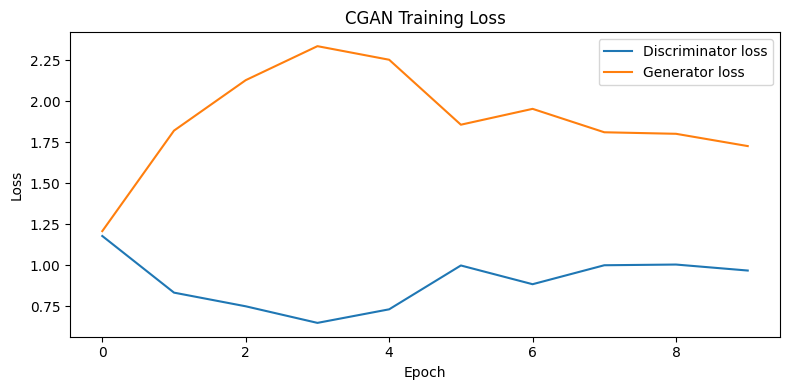

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(D_losses, label="Discriminator loss")
plt.plot(G_losses, label="Generator loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CGAN Training Loss")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT / "training_losses.png", dpi=150)
plt.show()

In [ ]:
import json
from pathlib import Path

OUTPUT.mkdir(parents=True, exist_ok=True)

with open(OUTPUT / "training_losses.json", "w") as f:
    json.dump({
        "generator_losses": G_losses,
        "discriminator_losses": D_losses,
        "epochs": len(G_losses),
        "image_size": IMAGE_SIZE,
        "batch_size": BATCH_SIZE,
        "latent_dim": LATENT_DIM,
        "class_names": class_names
    }, f, indent=2)

print("Baseline results saved:", OUTPUT)

Baseline results saved: /content/drive/MyDrive/ElevanceSkills_Project/Task1_Flower_Finetuning/final_results/task2_cgan


Generated samples for each flower label (baseline, 10 epochs):

In [ ]:
import matplotlib.pyplot as plt
import torch

G.eval()
images_per_class = 4

labels = torch.arange(NUM_CLASSES, device=device).repeat_interleave(
    images_per_class
)
noise = torch.randn(
    NUM_CLASSES * images_per_class, LATENT_DIM, device=device
)

with torch.no_grad():
    generated = G(noise, labels).cpu()

fig, axes = plt.subplots(
    NUM_CLASSES, images_per_class,
    figsize=(8, 10)
)

for i in range(NUM_CLASSES):
    for j in range(images_per_class):
        image = generated[i * images_per_class + j]
        image = (image.permute(1, 2, 0) + 1) / 2
        axes[i, j].imshow(image.clamp(0, 1))
        axes[i, j].set_title(class_names[i].capitalize(), fontsize=9)
        axes[i, j].axis("off")

plt.suptitle("CGAN Samples by Flower Class")
plt.tight_layout()
plt.savefig(OUTPUT / "class_sample_grid.png", dpi=150)
plt.show()

Real training images for comparison:

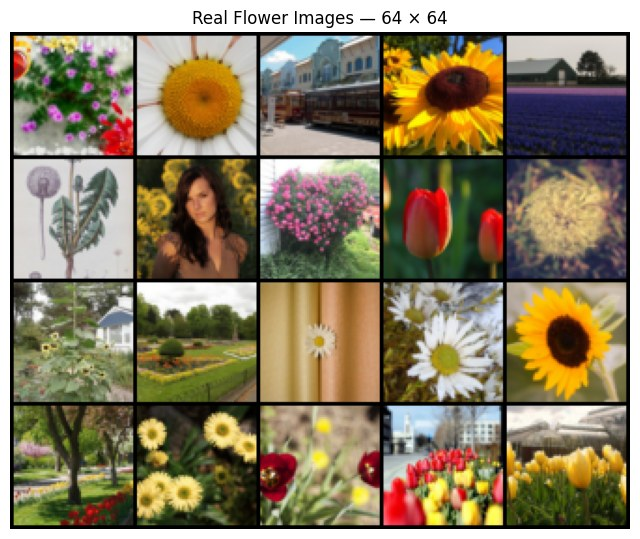

In [ ]:
import matplotlib.pyplot as plt
from torchvision.utils import make_grid

real_images, real_labels = next(iter(loader))

grid = make_grid(
    real_images[:20],
    nrow=5,
    normalize=True,
    value_range=(-1, 1)
)

plt.figure(figsize=(8, 8))
plt.imshow(grid.permute(1, 2, 0))
plt.title("Real Flower Images — 64 × 64")
plt.axis("off")
plt.show()

### 2.2 Improvement: continue training from epoch 10 to epoch 40

Each row is one epoch (10, 15, ... 40). The five images in a row are the five labels (daisy, dandelion, rose, sunflower, tulip), generated from the same fixed noise so progress can be compared.

In [ ]:
import torch
import torch.nn as nn
import torchvision.utils as vutils

# Separate output folder
EXTENDED_OUTPUT = OUTPUT / "cgan_extended_training"
EXTENDED_OUTPUT.mkdir(parents=True, exist_ok=True)

# Load original 10-epoch checkpoint
baseline_path = OUTPUT / "cgan_baseline_epoch10.pth"

checkpoint = torch.load(
    baseline_path,
    map_location=device,
    weights_only=False
)

G.load_state_dict(checkpoint["generator"])
D.load_state_dict(checkpoint["discriminator"])

# Use the original learning rates for this experiment
optimizer_G = torch.optim.Adam(
    G.parameters(), lr=0.0002, betas=(0.5, 0.999)
)
optimizer_D = torch.optim.Adam(
    D.parameters(), lr=0.0002, betas=(0.5, 0.999)
)

criterion = nn.BCEWithLogitsLoss()

# Fixed samples for comparison across epochs
torch.manual_seed(1234)
fixed_noise = torch.randn(NUM_CLASSES, LATENT_DIM, device=device)
fixed_labels = torch.arange(NUM_CLASSES, device=device)

G_losses_extended = []
D_losses_extended = []

print("Loaded checkpoint from epoch:", checkpoint["epoch"])
print("Saving new results to:", EXTENDED_OUTPUT)

Loaded checkpoint from epoch: 10
Saving new results to: /content/drive/MyDrive/ElevanceSkills_Project/Task1_Flower_Finetuning/final_results/task2_cgan/cgan_extended_training


In [ ]:
# Continue CGAN training from epoch 10 to epoch 40
# This trains for 30 additional epochs.

import torch
import torch.nn as nn
import torchvision.utils as vutils

TOTAL_EPOCHS = 40
START_EPOCH = 10
ADDITIONAL_EPOCHS = TOTAL_EPOCHS - START_EPOCH

criterion = nn.BCEWithLogitsLoss()

G.train()
D.train()

for epoch in range(START_EPOCH + 1, TOTAL_EPOCHS + 1):
    running_g_loss = 0.0
    running_d_loss = 0.0
    batches = 0

    for real_images, labels in loader:
        real_images = real_images.to(device)
        labels = labels.to(device)
        batch_size = real_images.size(0)

        real_targets = torch.full(
            (batch_size, 1), 0.9, device=device
        )
        fake_targets = torch.zeros(
            batch_size, 1, device=device
        )

        # -------------------------
        # 1. Train Discriminator
        # -------------------------
        optimizer_D.zero_grad(set_to_none=True)

        real_logits = D(real_images, labels)
        d_real_loss = criterion(real_logits, real_targets)

        noise = torch.randn(batch_size, LATENT_DIM, device=device)
        fake_images = G(noise, labels)

        fake_logits = D(fake_images.detach(), labels)
        d_fake_loss = criterion(fake_logits, fake_targets)

        d_loss = d_real_loss + d_fake_loss
        d_loss.backward()
        optimizer_D.step()

        # -------------------------
        # 2. Train Generator
        # -------------------------
        optimizer_G.zero_grad(set_to_none=True)

        noise = torch.randn(batch_size, LATENT_DIM, device=device)
        generated_images = G(noise, labels)
        generated_logits = D(generated_images, labels)

        g_targets = torch.ones(
            (batch_size, 1), device=device
        )
        g_loss = criterion(generated_logits, g_targets)

        g_loss.backward()
        optimizer_G.step()

        running_d_loss += d_loss.item()
        running_g_loss += g_loss.item()
        batches += 1

    avg_d_loss = running_d_loss / batches
    avg_g_loss = running_g_loss / batches

    G_losses_extended.append(avg_g_loss)
    D_losses_extended.append(avg_d_loss)

    print(
        f"Epoch {epoch}/{TOTAL_EPOCHS} | "
        f"D Loss: {avg_d_loss:.4f} | "
        f"G Loss: {avg_g_loss:.4f}"
    )

    # Generate samples using the same fixed noise and labels
    G.eval()
    with torch.no_grad():
        sample_images = G(fixed_noise, fixed_labels)
        sample_images = (sample_images + 1) / 2

        vutils.save_image(
            sample_images,
            EXTENDED_OUTPUT / f"samples_epoch_{epoch}.png",
            nrow=5
        )
    G.train()

    # Save checkpoint after every epoch
    torch.save(
        {
            "epoch": epoch,
            "generator": G.state_dict(),
            "discriminator": D.state_dict(),
            "optimizer_G": optimizer_G.state_dict(),
            "optimizer_D": optimizer_D.state_dict(),
            "generator_loss": avg_g_loss,
            "discriminator_loss": avg_d_loss,
            "class_names": dataset.classes,
        },
        EXTENDED_OUTPUT / "cgan_extended_checkpoint.pth"
    )

print("Training completed.")
print(f"Total epochs completed: {TOTAL_EPOCHS}")
print(f"Results saved in: {EXTENDED_OUTPUT}")

Epoch 11/40 | D Loss: 0.9133 | G Loss: 2.0022
Epoch 12/40 | D Loss: 0.9036 | G Loss: 2.0661
Epoch 13/40 | D Loss: 0.9201 | G Loss: 2.0799
Epoch 14/40 | D Loss: 0.8847 | G Loss: 2.0377
Epoch 15/40 | D Loss: 0.9186 | G Loss: 2.0297
Epoch 16/40 | D Loss: 0.8745 | G Loss: 2.0310
Epoch 17/40 | D Loss: 0.8867 | G Loss: 2.1565
Epoch 18/40 | D Loss: 0.8449 | G Loss: 2.1861
Epoch 19/40 | D Loss: 0.8839 | G Loss: 2.1200
Epoch 20/40 | D Loss: 0.8329 | G Loss: 2.2142
Epoch 21/40 | D Loss: 0.9070 | G Loss: 2.0991
Epoch 22/40 | D Loss: 0.8405 | G Loss: 2.1359
Epoch 23/40 | D Loss: 0.8355 | G Loss: 2.1737
Epoch 24/40 | D Loss: 0.8698 | G Loss: 2.2149
Epoch 25/40 | D Loss: 0.8763 | G Loss: 2.1301
Epoch 26/40 | D Loss: 0.8594 | G Loss: 2.1134
Epoch 27/40 | D Loss: 0.8320 | G Loss: 2.1980
Epoch 28/40 | D Loss: 0.8553 | G Loss: 2.1694
Epoch 29/40 | D Loss: 0.8011 | G Loss: 2.2149
Epoch 30/40 | D Loss: 0.8718 | G Loss: 2.1995
Epoch 31/40 | D Loss: 0.8693 | G Loss: 2.1949
Epoch 32/40 | D Loss: 0.8352 | G L

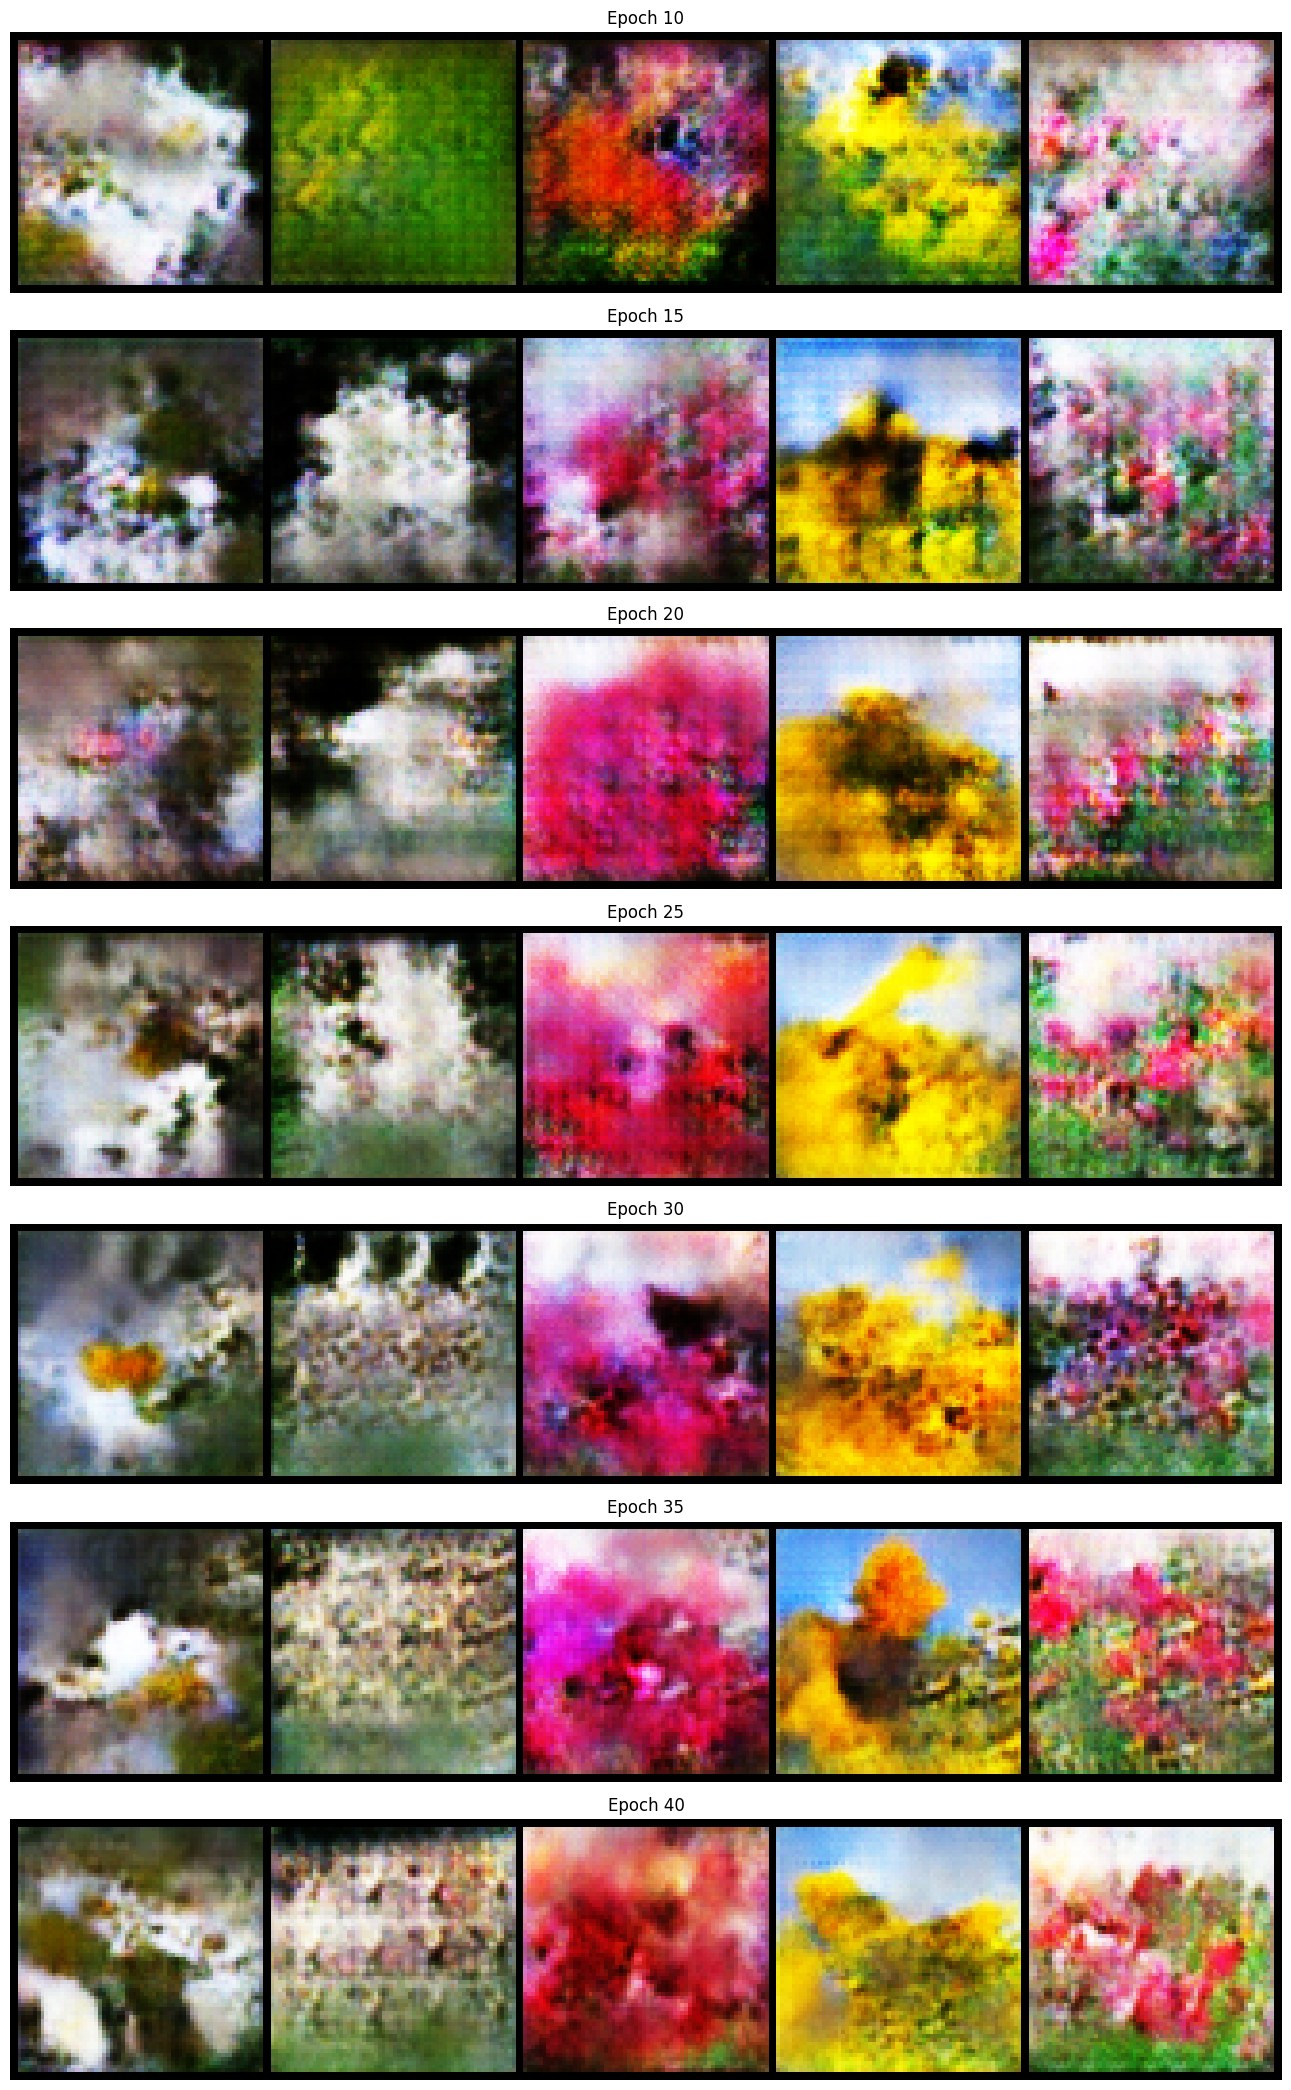

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# Include the original baseline and selected extended-training epochs
epochs_to_view = [10, 15, 20, 25, 30, 35, 40]

fig, axes = plt.subplots(
    len(epochs_to_view), 1,
    figsize=(15, 3 * len(epochs_to_view))
)

for ax, epoch in zip(axes, epochs_to_view):
    if epoch == 10:
        # Original baseline sample, if this file exists
        image_path = OUTPUT / "samples_epoch_10.png"
    else:
        image_path = (
            EXTENDED_OUTPUT / f"samples_epoch_{epoch}.png"
        )

    if image_path.exists():
        image = Image.open(image_path)
        ax.imshow(image)
        ax.set_title(f"Epoch {epoch}")
        ax.axis("off")
    else:
        ax.text(0.5, 0.5, f"Missing: {image_path.name}",
                ha="center", va="center")
        ax.axis("off")

plt.tight_layout()
plt.show()

Generate by label name. The trained CGAN (epoch 40) takes a text label such as `"rose"` and maps it to its class index through `class_names`:

In [ ]:
from torchvision.utils import make_grid

@torch.no_grad()
def generate_cgan_by_label(label_name, n=8, seed=0, show=True):
    """Generate n flower images of the requested category, e.g. generate_cgan_by_label("rose")."""
    name = label_name.strip().lower()
    if name not in class_names:
        raise ValueError(f"Unknown label '{label_name}'. Available labels: {class_names}")
    label_id = class_names.index(name)

    noise_gen = torch.Generator(device="cpu").manual_seed(seed)
    noise = torch.randn(n, LATENT_DIM, generator=noise_gen).to(device)
    labels = torch.full((n,), label_id, dtype=torch.long, device=device)

    G.eval()
    images = (G(noise, labels).cpu().clamp(-1, 1) + 1) / 2

    if show:
        grid = make_grid(images, nrow=n, padding=2)
        plt.figure(figsize=(2 * n, 2.4))
        plt.imshow(grid.permute(1, 2, 0))
        plt.title(f'label = "{name}"')
        plt.axis("off")
        plt.show()
    return images

_ = generate_cgan_by_label("rose")          # one requested label ...
for label in class_names:                   # ... and every available label
    _ = generate_cgan_by_label(label, n=6, seed=1)

---
# Task 3 — Text preprocessing with Hugging Face Transformers

Text descriptions are tokenized and encoded with the pre-trained CLIP text model (`openai/clip-vit-base-patch32`).
The resulting token embeddings are the inputs used by the text-conditioned GAN in Task 5 and the pipeline in Task 6.

In [ ]:
from transformers import CLIPTokenizer, CLIPTextModel

MODEL_NAME = "openai/clip-vit-base-patch32"

tokenizer = CLIPTokenizer.from_pretrained(MODEL_NAME)
text_encoder = CLIPTextModel.from_pretrained(MODEL_NAME).to(DEVICE)
text_encoder.eval()
for param in text_encoder.parameters():      # CLIP is used as a frozen encoder
    param.requires_grad = False

print("Device:", DEVICE)
print("Model:", MODEL_NAME)

In [ ]:
flower_prompts = [
    "A photograph of white daisies growing in a garden.",
    "A close-up photograph of a dandelion flower.",
    "A photograph of a pink rose in bloom.",
    "A field of bright yellow sunflowers.",
    "A photograph of colorful tulips growing in a garden."
]

for prompt in flower_prompts:
    print(prompt)

A photograph of white daisies growing in a garden.
A close-up photograph of a dandelion flower.
A photograph of a pink rose in bloom.
A field of bright yellow sunflowers.
A photograph of colorful tulips growing in a garden.


In [ ]:
tokens = tokenizer(
    flower_prompts,
    padding=True,
    truncation=True,
    max_length=77,
    return_tensors="pt"
)

print("Input IDs shape:", tokens["input_ids"].shape)
print("Attention mask shape:", tokens["attention_mask"].shape)

print("\nExample prompt:")
print(flower_prompts[0])

print("\nToken IDs:")
print(tokens["input_ids"][0].tolist())

print("\nReadable tokens:")
print(tokenizer.convert_ids_to_tokens(tokens["input_ids"][0]))

Input IDs shape: torch.Size([5, 12])
Attention mask shape: torch.Size([5, 12])

Example prompt:
A photograph of white daisies growing in a garden.

Token IDs:
[49406, 320, 8853, 539, 1579, 40654, 4425, 530, 320, 2756, 269, 49407]

Readable tokens:
['<|startoftext|>', 'a</w>', 'photograph</w>', 'of</w>', 'white</w>', 'daisies</w>', 'growing</w>', 'in</w>', 'a</w>', 'garden</w>', '.</w>', '<|endoftext|>']


In [ ]:
tokens = {key: value.to(DEVICE) for key, value in tokens.items()}

with torch.no_grad():
    outputs = text_encoder(**tokens)

last_hidden_state = outputs.last_hidden_state

# CLIP's pooled text representation
text_embeddings = outputs.pooler_output

print("Token-level embeddings:", last_hidden_state.shape)
print("Pooled text embeddings:", text_embeddings.shape)

Token-level embeddings: torch.Size([5, 12, 512])
Pooled text embeddings: torch.Size([5, 512])


In [ ]:
import torch.nn.functional as F
import pandas as pd

normalized = F.normalize(text_embeddings, p=2, dim=1)
similarity = normalized @ normalized.T

similarity_df = pd.DataFrame(
    similarity.cpu().numpy(),
    index=["Daisy", "Dandelion", "Rose", "Sunflower", "Tulip"],
    columns=["Daisy", "Dandelion", "Rose", "Sunflower", "Tulip"]
)

display(similarity_df.round(3))

,Daisy,Dandelion,Rose,Sunflower,Tulip
Daisy,1.000,0.559,0.413,0.482,0.530
Dandelion,0.559,1.000,0.408,0.499,0.385
Rose,0.413,0.408,1.000,0.313,0.467
Sunflower,0.482,0.499,0.313,1.000,0.418
Tulip,0.530,0.385,0.467,0.418,1.000


In [ ]:
from pathlib import Path
import json
import numpy as np

T3_OUT = OUTPUTS / "task3_text_preprocessing"
T3_OUT.mkdir(parents=True, exist_ok=True)

np.save(
    T3_OUT / "flower_text_embeddings.npy",
    text_embeddings.cpu().numpy()
)

with open(T3_OUT / "flower_prompts.json", "w") as f:
    json.dump(flower_prompts, f, indent=2)

similarity_df.to_csv(T3_OUT / "text_similarity.csv")

print("Saved outputs to:", T3_OUT)

---
# Task 4 — Load and explore a public dataset

Dataset: public 5-class flower photo collection (Creative Commons licensed Flickr images; see the license printed at the end of this section).
Covered: number of classes, images per class, image resolution/format, sample photos, and the text descriptions available for the images.

In [ ]:
assert DATASET.exists(), f"Dataset not found: {DATASET}"
print("Dataset found:", DATASET)

In [ ]:
class_counts = {}

for folder in sorted(DATASET.iterdir()):
    if folder.is_dir():
        count = sum(
            1 for file in folder.rglob("*")
            if file.is_file() and file.suffix.lower() in IMAGE_EXTS
        )
        class_counts[folder.name] = count

df_classes = pd.DataFrame(
    class_counts.items(),
    columns=["Flower Class", "Image Count"]
)

df_classes = df_classes.sort_values(
    "Image Count", ascending=False
).reset_index(drop=True)

display(df_classes)

print("Total images:", df_classes["Image Count"].sum())
print("Total classes:", len(df_classes))

,Flower Class,Image Count
0,dandelion,646
1,tulip,607
2,daisy,516
3,rose,497
4,sunflower,495


Total images: 2761
Total classes: 5


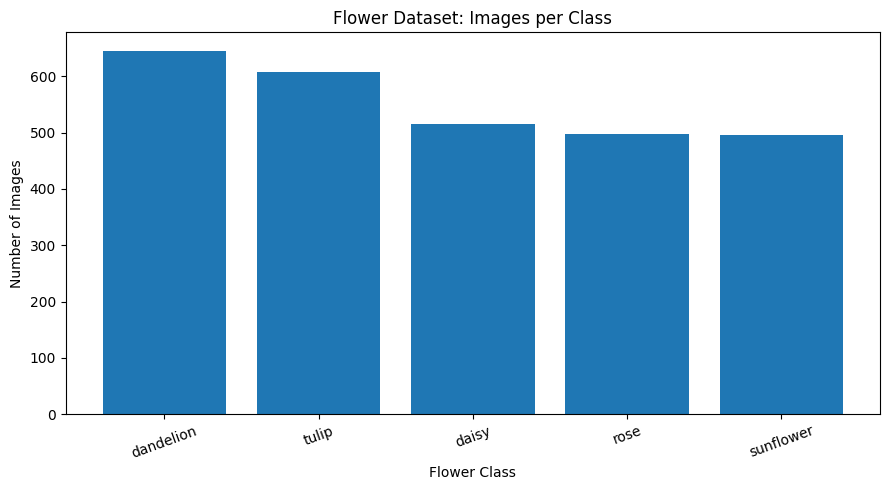

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    df_classes["Flower Class"],
    df_classes["Image Count"]
)

plt.title("Flower Dataset: Images per Class")
plt.xlabel("Flower Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
records = []
errors = []

for folder in sorted(DATASET.iterdir()):
    if not folder.is_dir():
        continue

    for file in folder.rglob("*"):
        if not file.is_file() or file.suffix.lower() not in IMAGE_EXTS:
            continue

        try:
            with Image.open(file) as img:
                width, height = img.size

                records.append({
                    "Class": folder.name,
                    "Filename": file.name,
                    "Width": width,
                    "Height": height,
                    "Resolution": width * height,
                    "Mode": img.mode,
                    "Format": img.format
                })

        except Exception as e:
            errors.append({
                "File": str(file),
                "Error": str(e)
            })

df_images = pd.DataFrame(records)

print("Images successfully inspected:", len(df_images))
print("Unreadable images:", len(errors))

display(df_images.head(10))

Images successfully inspected: 2761
Unreadable images: 0


,Class,Filename,Width,Height,Resolution,Mode,Format
0,daisy,9922116524_ab4a2533fe_n.jpg,320,240,76800,RGB,JPEG
1,daisy,9496209717_25a6ebdab6_m.jpg,240,240,57600,RGB,JPEG
2,daisy,9321854387_5f77c926cb_n (1).jpg,320,213,68160,RGB,JPEG
3,daisy,9321854387_5f77c926cb_n.jpg,320,213,68160,RGB,JPEG
4,daisy,9180706736_092d43088c (1).jpg,500,339,169500,RGB,JPEG
5,daisy,9180706736_092d43088c.jpg,500,339,169500,RGB,JPEG
6,daisy,9593034725_0062f0d24e_n.jpg,320,213,68160,RGB,JPEG
7,daisy,9054268881_19792c5203_n.jpg,320,243,77760,RGB,JPEG
8,daisy,8740807508_0587f5b7b7.jpg,500,317,158500,RGB,JPEG
9,daisy,9204730092_a7f2182347 (1).jpg,500,332,166000,RGB,JPEG


In [ ]:
print("Image dimension statistics:")
display(df_images[["Width", "Height", "Resolution"]].describe())

print("Most common image dimensions:")
display(
    df_images.groupby(["Width", "Height"])
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
    .head(10)
)

print("Image formats:")
display(df_images["Format"].value_counts())

print("Image modes:")
display(df_images["Mode"].value_counts())

Image dimension statistics:


,Width,Height,Resolution
count,2761.000000,2761.000000,2761.000000
mean,362.563202,268.066643,101702.677291
std,116.959716,47.910158,48797.608361
min,143.000000,159.000000,34320.000000
25%,320.000000,240.000000,68160.000000
50%,320.000000,240.000000,76800.000000
75%,500.000000,332.000000,166000.000000
max,1024.000000,441.000000,220500.000000


Most common image dimensions:


,Width,Height,Count
256,500,333,528
140,320,240,433
113,320,213,285
104,240,240,181
25,180,240,103
255,500,332,101
7,159,240,69
257,500,334,52
254,500,331,52
215,500,281,44


Image formats:


,count
Format,
JPEG,2761


Image modes:


,count
Mode,
RGB,2761


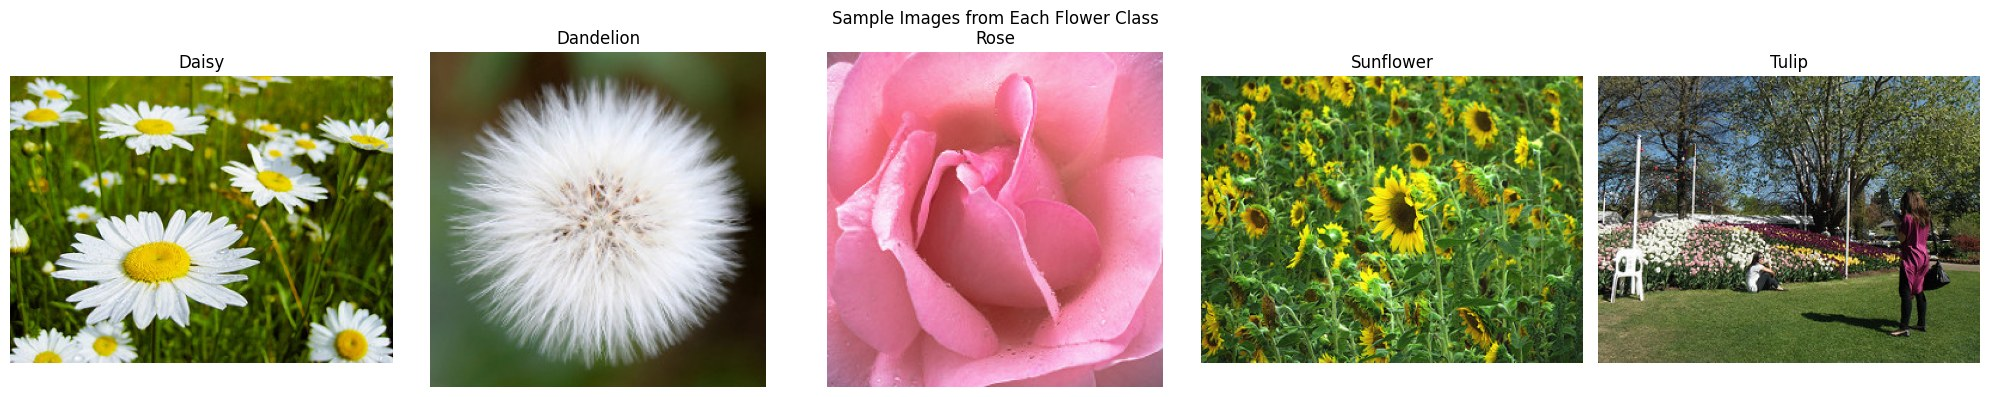

In [ ]:
classes = sorted(
    folder.name for folder in DATASET.iterdir()
    if folder.is_dir()
)

fig, axes = plt.subplots(
    1, len(classes),
    figsize=(4 * len(classes), 4)
)

for ax, flower_class in zip(axes, classes):
    folder = DATASET / flower_class

    files = [
        f for f in folder.rglob("*")
        if f.is_file() and f.suffix.lower() in IMAGE_EXTS
    ]

    with Image.open(files[0]) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(flower_class.capitalize())
    ax.axis("off")

plt.suptitle("Sample Images from Each Flower Class")
plt.tight_layout()
plt.show()

In [ ]:
caption_extensions = {".csv", ".json", ".jsonl", ".txt", ".tsv"}

caption_files = [
    p for p in DATASET.parent.rglob("*")
    if p.is_file() and p.suffix.lower() in caption_extensions
]

for p in caption_files[:50]:
    print(p)

print("Possible annotation files found:", len(caption_files))

/content/drive/MyDrive/ElevanceSkills_Project/Task1_Flower_Finetuning/dataset/task1_image_dataset/LICENSE.txt
/content/drive/MyDrive/ElevanceSkills_Project/Task1_Flower_Finetuning/dataset/task1_image_dataset/Testing_set_flower.csv
/content/drive/MyDrive/ElevanceSkills_Project/Task1_Flower_Finetuning/dataset/task1_image_dataset/sample_submission.csv
Possible annotation files found: 3


### Text descriptions and description length

This dataset ships with class folders only — there are no human-written captions (the annotation search above finds only a license file and the test-set CSVs).
The text paired with each image is therefore the template caption used for Task 1, `a photograph of a <class> flower`.
Below: description length (words and CLIP tokens) and images displayed together with their descriptions.
Every caption here follows one template, so the length analysis is intentionally simple; section 4.2 repeats the analysis on the Oxford-102 subset used in Tasks 5-6, where description length varies between classes and human-written captions are loaded when available.

In [ ]:
caption_df = df_images[["Class"]].copy()
caption_df["Caption"] = caption_df["Class"].map(lambda c: f"a photograph of a {c} flower")
caption_df["Words"] = caption_df["Caption"].str.split().str.len()
caption_df["CLIP tokens"] = [len(ids) for ids in tokenizer(caption_df["Caption"].tolist())["input_ids"]]

print("Description length of the template captions (all images):")
display(caption_df.groupby("Class")[["Words", "CLIP tokens"]].agg(["min", "mean", "max"]))

print("Description length of the descriptive prompts from Task 3:")
display(pd.DataFrame({
    "Prompt": flower_prompts,
    "Words": [len(p.split()) for p in flower_prompts],
    "CLIP tokens": [len(tokenizer(p)["input_ids"]) for p in flower_prompts],
}))

# Photos shown together with their descriptions
fig, axes = plt.subplots(1, len(classes), figsize=(4 * len(classes), 4.5))
for ax, flower_class in zip(axes, classes):
    first_file = next(f for f in sorted((DATASET / flower_class).rglob("*")) if f.suffix.lower() in IMAGE_EXTS)
    with Image.open(first_file) as img:
        ax.imshow(img.convert("RGB"))
    ax.set_title(f"a photograph of a\n{flower_class} flower", fontsize=11)
    ax.axis("off")
plt.suptitle("Photos with their text descriptions")
plt.tight_layout()
plt.show()

In [ ]:
T4_OUT = OUTPUTS / "task4_dataset_analysis"

T4_OUT.mkdir(parents=True, exist_ok=True)

df_classes.to_csv(T4_OUT / "class_counts.csv", index=False)
df_images.to_csv(T4_OUT / "image_metadata.csv", index=False)

plt.figure(figsize=(9, 5))
plt.bar(df_classes["Flower Class"], df_classes["Image Count"])
plt.title("Flower Dataset: Images per Class")
plt.xlabel("Flower Class")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.savefig(T4_OUT / "class_distribution.png", dpi=150)
plt.close()

summary = f"""
Flower Dataset Analysis

Total readable images: {len(df_images)}
Total classes: {len(classes)}
Unreadable images: {len(errors)}

Class counts:
{df_classes.to_string(index=False)}

Image dimensions:
{df_images[['Width', 'Height', 'Resolution']].describe().to_string()}
"""

(T4_OUT / "analysis_summary.txt").write_text(summary)

print("Saved results to:", T4_OUT)

In [ ]:
from pathlib import Path
import pandas as pd

ROOT = DATASET.parent

for name in ["Testing_set_flower.csv", "sample_submission.csv"]:
    path = ROOT / name

    if path.exists():
        print(f"\n--- {name} ---")
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df.head(5))


--- Testing_set_flower.csv ---
Shape: (924, 1)
Columns: ['filename']


,filename
0,Image_1.jpg
1,Image_2.jpg
2,Image_3.jpg
3,Image_4.jpg
4,Image_5.jpg



--- sample_submission.csv ---
Shape: (924, 1)
Columns: ['prediction']


,prediction
0,sunflower
1,sunflower
2,sunflower
3,sunflower
4,sunflower


In [ ]:
license_path = ROOT / "LICENSE.txt"

if license_path.exists():
    print(license_path.read_text()[:5000])

All images in this archive are licensed under the Creative Commons By-Attribution License, available at:
https://creativecommons.org/licenses/by/2.0/
The photographers are listed below, thanks to all of them for making their work available, and please be sure to credit them for any use as per the license.

daisy/7568630428_8cf0fc16ff_n.jpg CC-BY by A Guy Taking Pictures - https://www.flickr.com/photos/80901381@N04/7568630428/
daisy/7410356270_9dff4d0e2e_n.jpg CC-BY by martinak15 - https://www.flickr.com/photos/martinaphotography/7410356270/
daisy/4286053334_a75541f20b_m.jpg CC-BY by jenny downing - https://www.flickr.com/photos/jenny-pics/4286053334/
daisy/10770585085_4742b9dac3_n.jpg CC-BY by Thangaraj Kumaravel - https://www.flickr.com/photos/kumaravel/10770585085/
daisy/8759177308_951790e00d_m.jpg CC-BY by Marina del Castell - https://www.flickr.com/photos/marinadelcastell/8759177308/
daisy/4131565290_0585c4dd5a_n.jpg CC-BY by jenny downing - https://www.flickr.com/photos/jenny-pics

### 4.2 Oxford-102 Flowers — the dataset used by Tasks 5–6

Tasks 5–6 train on the **40 Oxford-102 classes with the most images** (re-numbered 0–39). This section builds that subset (or loads `dataset_40class.csv` when it already exists) and repeats the dataset analysis on it: number of classes, images per class, image resolution, description length, and photos shown together with their descriptions.

Oxford-102 does not ship text descriptions either, so each image is paired with the template description `a photograph of a <flower name> flower` — the same text that Tasks 5–6 give to CLIP. Flower names differ in length, so description length now varies between classes. If you also have the human-written Oxford-102 captions (Reed et al., 10 per image, folder `text_c10`), the last cell of this section loads and analyses them.

In [ ]:
OXFORD_JPG = first_existing(*[
    root / "task1_image_dataset" / "train" / "102flowers" / "jpg" for root in DATASET_ROOTS
])
INDEX_CSV = OUTPUTS / "task2_40class_cgan" / "dataset_40class.csv"
INDEX_CSV.parent.mkdir(parents=True, exist_ok=True)
N_OXFORD_CLASSES = 40

# Official Oxford-102 class names, ordered by label 1..102 (same list as torchvision and tensorflow-datasets)
OXFORD_102_NAMES = [
    'pink primrose', 'hard-leaved pocket orchid', 'canterbury bells', 'sweet pea',
    'english marigold', 'tiger lily', 'moon orchid', 'bird of paradise', 'monkshood',
    'globe thistle', 'snapdragon', "colt's foot", 'king protea', 'spear thistle', 'yellow iris',
    'globe-flower', 'purple coneflower', 'peruvian lily', 'balloon flower',
    'giant white arum lily', 'fire lily', 'pincushion flower', 'fritillary', 'red ginger',
    'grape hyacinth', 'corn poppy', 'prince of wales feathers', 'stemless gentian', 'artichoke',
    'sweet william', 'carnation', 'garden phlox', 'love in the mist', 'mexican aster',
    'alpine sea holly', 'ruby-lipped cattleya', 'cape flower', 'great masterwort', 'siam tulip',
    'lenten rose', 'barbeton daisy', 'daffodil', 'sword lily', 'poinsettia', 'bolero deep blue',
    'wallflower', 'marigold', 'buttercup', 'oxeye daisy', 'common dandelion', 'petunia',
    'wild pansy', 'primula', 'sunflower', 'pelargonium', 'bishop of llandaff', 'gaura', 'geranium',
    'orange dahlia', 'pink-yellow dahlia?', 'cautleya spicata', 'japanese anemone',
    'black-eyed susan', 'silverbush', 'californian poppy', 'osteospermum', 'spring crocus',
    'bearded iris', 'windflower', 'tree poppy', 'gazania', 'azalea', 'water lily', 'rose',
    'thorn apple', 'morning glory', 'passion flower', 'lotus', 'toad lily', 'anthurium',
    'frangipani', 'clematis', 'hibiscus', 'columbine', 'desert-rose', 'tree mallow', 'magnolia',
    'cyclamen', 'watercress', 'canna lily', 'hippeastrum', 'bee balm', 'ball moss', 'foxglove',
    'bougainvillea', 'camellia', 'mallow', 'mexican petunia', 'bromelia', 'blanket flower',
    'trumpet creeper', 'blackberry lily'
]
assert len(OXFORD_102_NAMES) == 102


def build_oxford_subset_index(jpg_dir, n_classes=N_OXFORD_CLASSES):
    """Index of the n most populated Oxford-102 classes: DataFrame(path, class_id, class_name, oxford_label)."""
    from scipy.io import loadmat

    label_files = sorted(jpg_dir.parents[2].rglob("imagelabels.mat"))
    if not label_files:
        raise FileNotFoundError(
            f"imagelabels.mat (the Oxford-102 image labels) was not found under {jpg_dir.parents[2]}. "
            "Download it from the Oxford-102 Flowers page and place it next to the 102flowers folder, "
            "or provide dataset_40class.csv."
        )
    # label (1-102) of image_00001.jpg, image_00002.jpg, ...
    labels = loadmat(label_files[0])["labels"].ravel().astype(int)

    counts = pd.Series(labels).value_counts()
    ranking = (pd.DataFrame({"oxford_label": counts.index.astype(int), "n_images": counts.values})
               .sort_values(["n_images", "oxford_label"], ascending=[False, True])
               .head(n_classes).reset_index(drop=True))
    new_id = {int(label): class_id for class_id, label in enumerate(ranking["oxford_label"])}

    rows = []
    for image_number, label in enumerate(labels, start=1):
        if int(label) not in new_id:
            continue
        path = jpg_dir / f"image_{image_number:05d}.jpg"
        if not path.is_file():
            raise FileNotFoundError(f"Missing image: {path}")
        rows.append({"path": str(path), "class_id": new_id[int(label)],
                     "class_name": OXFORD_102_NAMES[int(label) - 1], "oxford_label": int(label)})
    return pd.DataFrame(rows).sort_values(["class_id", "path"]).reset_index(drop=True)


if INDEX_CSV.is_file():
    oxford_df = pd.read_csv(INDEX_CSV)
    print("Loaded existing index:", INDEX_CSV)
else:
    oxford_df = build_oxford_subset_index(OXFORD_JPG)
    oxford_df.to_csv(INDEX_CSV, index=False)
    print("Built and saved index:", INDEX_CSV)


def repair_path(old_path):
    """The index may come from another Drive layout: point every path at the current image folder."""
    candidate = OXFORD_JPG / Path(str(old_path)).name
    return str(candidate) if candidate.exists() else str(old_path)


oxford_df["path"] = oxford_df["path"].apply(repair_path)
oxford_df = oxford_df.reset_index(drop=True)
missing = ~oxford_df["path"].apply(lambda p: Path(p).is_file())
if missing.any():
    print(oxford_df.loc[missing, "path"].head(10).to_string(index=False))
    raise FileNotFoundError(f"{int(missing.sum())} image paths are missing. Training has not started.")


def make_prompt(name):
    """Template description used everywhere in this notebook."""
    name = name.replace("?", "").strip()
    if name.lower().endswith("flower"):
        return f"a photograph of a {name}"
    return f"a photograph of a {name} flower"


print(f"Oxford-102 subset: {len(oxford_df)} images | {oxford_df['class_id'].nunique()} classes")

In [ ]:
# ---- classes and images per class ----
class_table = (oxford_df.groupby(["class_id", "class_name"]).size()
               .reset_index(name="Image Count")
               .sort_values("Image Count", ascending=False).reset_index(drop=True))

print("Total classes:", len(class_table), "| total images:", int(class_table["Image Count"].sum()))
print("Images per class (min / mean / max):",
      int(class_table["Image Count"].min()),
      round(class_table["Image Count"].mean(), 1),
      int(class_table["Image Count"].max()))
display(class_table.head(10))

by_id = class_table.sort_values("class_id")
plt.figure(figsize=(13, 5))
plt.bar(by_id["class_id"].astype(str), by_id["Image Count"])
plt.title("Oxford-102 subset: images per class")
plt.xlabel("Class ID")
plt.ylabel("Number of images")
plt.tight_layout()
plt.show()

# ---- image resolution, mode and format ----
size_rows = []
for image_path in oxford_df["path"]:
    with Image.open(image_path) as img:
        size_rows.append((img.width, img.height, img.mode, img.format))
size_df = pd.DataFrame(size_rows, columns=["Width", "Height", "Mode", "Format"])
size_df["Resolution"] = size_df["Width"] * size_df["Height"]

print("Image dimension statistics:")
display(size_df[["Width", "Height", "Resolution"]].describe())
print("Most common image dimensions:")
display(size_df.groupby(["Width", "Height"]).size().reset_index(name="Count")
        .sort_values("Count", ascending=False).head(5))
print("Image formats:", size_df["Format"].value_counts().to_dict(),
      "| modes:", size_df["Mode"].value_counts().to_dict())

class_table.to_csv(T4_OUT / "oxford40_class_counts.csv", index=False)
size_df.describe().to_csv(T4_OUT / "oxford40_image_size_stats.csv")

In [ ]:
# ---- description length and photos shown with their descriptions ----
oxford_df["Description"] = oxford_df["class_name"].map(make_prompt)
oxford_df["Words"] = oxford_df["Description"].str.split().str.len()
oxford_df["CLIP tokens"] = [len(ids) for ids in tokenizer(oxford_df["Description"].tolist())["input_ids"]]

print(f"Description length of the template descriptions ({len(oxford_df)} images):")
display(oxford_df[["Words", "CLIP tokens"]].agg(["min", "mean", "median", "max"]).round(2))

per_class = oxford_df.drop_duplicates("class_id").sort_values("CLIP tokens")
print("Shortest:", per_class.iloc[0]["Description"], f"({per_class.iloc[0]['CLIP tokens']} CLIP tokens)")
print("Longest: ", per_class.iloc[-1]["Description"], f"({per_class.iloc[-1]['CLIP tokens']} CLIP tokens)")

plt.figure(figsize=(7, 3.5))
plt.hist(oxford_df["CLIP tokens"], bins=range(int(oxford_df["CLIP tokens"].min()), int(oxford_df["CLIP tokens"].max()) + 2))
plt.title("Description length in CLIP tokens (incl. start/end tokens)")
plt.xlabel("CLIP tokens")
plt.ylabel("Images")
plt.tight_layout()
plt.show()

sample = oxford_df.groupby("class_id").head(1).sort_values("class_id").iloc[::5].head(8)
fig, axes = plt.subplots(2, 4, figsize=(16, 8.5))
for ax in axes.flat:
    ax.axis("off")
for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    with Image.open(row["path"]) as img:
        ax.imshow(img.convert("RGB"))
    ax.set_title(f"{row['Description']}\n(class {row['class_id']})", fontsize=9)
plt.suptitle("Oxford-102 photos with their text descriptions")
plt.tight_layout()
plt.show()

oxford_df[["path", "class_id", "class_name", "Description", "Words", "CLIP tokens"]].to_csv(
    T4_OUT / "oxford40_descriptions.csv", index=False)

In [ ]:
# ---- optional: human-written Oxford-102 captions (Reed et al.: 10 captions per image, one .txt file per image) ----
import textwrap

CAPTION_DIR_CANDIDATES = [
    PROJECT_ROOT / "flowers_captions" / "text_c10",
    PROJECT_ROOT / "text_c10",
    OXFORD_JPG.parent / "text_c10",
]
REED_CAPTIONS = next((p for p in CAPTION_DIR_CANDIDATES if p.is_dir()), None)

if REED_CAPTIONS is None:
    print("Human-written captions not found, so the analysis above uses the template descriptions.")
    print("To analyse real captions, place the Oxford-102 caption folder 'text_c10' in one of:")
    for p in CAPTION_DIR_CANDIDATES:
        print("  ", p)
else:
    caption_files = {p.stem: p for p in REED_CAPTIONS.rglob("image_*.txt")}

    def read_captions(image_path):
        txt = caption_files.get(Path(image_path).stem)
        if txt is None:
            return []
        lines = txt.read_text(encoding="utf-8", errors="ignore").splitlines()
        return [line.strip() for line in lines if line.strip()]

    oxford_df["Captions"] = oxford_df["path"].map(read_captions)
    has_captions = oxford_df["Captions"].str.len() > 0
    print(f"Images with captions: {int(has_captions.sum())}/{len(oxford_df)}")

    cap_df = pd.DataFrame(
        [(row.class_name, caption) for row in oxford_df[has_captions].itertuples() for caption in row.Captions],
        columns=["Class", "Caption"],
    )
    cap_df["Words"] = cap_df["Caption"].str.split().str.len()
    cap_df["CLIP tokens"] = [len(ids) for ids in tokenizer(cap_df["Caption"].tolist())["input_ids"]]

    print(f"{len(cap_df)} captions, {len(cap_df) / max(int(has_captions.sum()), 1):.1f} per image")
    display(cap_df[["Words", "CLIP tokens"]].describe().round(2))
    print("Captions longer than CLIP's 77-token limit:", int((cap_df["CLIP tokens"] > 77).sum()))

    shown = oxford_df[has_captions].groupby("class_id").head(1).sort_values("class_id").iloc[::10].head(4)
    fig, axes = plt.subplots(1, len(shown), figsize=(4.5 * len(shown), 5.5), squeeze=False)
    for ax, (_, row) in zip(axes[0], shown.iterrows()):
        with Image.open(row["path"]) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(row["class_name"].capitalize(), fontsize=10)
        ax.set_xlabel(textwrap.fill(row["Captions"][0], 40), fontsize=8)
        ax.set_xticks([]); ax.set_yticks([])
    plt.suptitle("Oxford-102 photos with human-written captions")
    plt.tight_layout()
    plt.show()

---
# Task 5 — Improve the GAN with attention

Two attention mechanisms are added to a class-conditional GAN trained on the 40-class Oxford-102 subset (64x64):

1. **Self-attention** (SAGAN-style) at 16x16 resolution in the generator, so distant image regions can inform each other.
2. **Text cross-attention**: image features attend over the 77 CLIP token embeddings of the flower description, so the generator can focus on the relevant parts of the text.

Training uses the hinge loss, spectral-normalised projection discriminator, and a lower generator learning rate (1e-4) than discriminator (2e-4).

### 5.1 Dataset (40-class Oxford-102 subset)

The 40-class index (`dataset_40class.csv`) is built — or loaded, if it already exists — in section 4.2 (the 40 Oxford-102 classes with the most images, re-numbered 0–39). Its image paths are already repaired and checked there.

In [ ]:
df = oxford_df.copy()      # index built or loaded in section 4.2; image paths already repaired and checked

TASK5_DIR = OUTPUTS / "task5_attention_cgan_40class"
TASK5_DIR.mkdir(parents=True, exist_ok=True)
REPAIRED_CSV = TASK5_DIR / "dataset_40class_repaired.csv"
df.to_csv(REPAIRED_CSV, index=False)
INDEX_CSV = REPAIRED_CSV

print("Index saved:", INDEX_CSV)
print("\nClass count:", df["class_id"].nunique())
print(df["class_name"].value_counts().head())

In [ ]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.utils import save_image, make_grid

NUM_CLASSES = 40
LATENT_DIM = 128
IMAGE_SIZE = 64
BATCH_SIZE = 32

class_names = {int(i): str(n) for i, n in
               df[["class_id", "class_name"]].drop_duplicates().sort_values("class_id").itertuples(index=False)}
assert sorted(class_names) == list(range(NUM_CLASSES)), "Class IDs must be 0-39."

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

class FlowerDataset40(Dataset):
    def __init__(self, dataframe, transform=None):
        self.data = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        image = Image.open(row["path"]).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, int(row["class_id"])      # class IDs are 0-39

dataset = FlowerDataset40(df, transform=transform)
image, label = dataset[0]
print("Images:", len(dataset), "| classes:", len(class_names))
print("Sample:", tuple(image.shape), "label", label, "=", class_names[label])

### 5.2 Generator with self-attention, and projection discriminator

In [ ]:
import random

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# -------------------------
# Residual generator blocks, self-attention, generator
# -------------------------
class GBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.bn1 = nn.BatchNorm2d(in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.skip = nn.Conv2d(in_ch, out_ch, 1)

    def forward(self, x):
        up = F.interpolate(x, scale_factor=2, mode="nearest")
        h = self.conv1(F.relu(self.bn1(up), inplace=False))
        h = self.conv2(F.relu(self.bn2(h), inplace=False))
        return h + self.skip(up)


class SelfAttention(nn.Module):
    def __init__(self, channels):
        super().__init__()
        hidden = max(channels // 8, 1)
        self.query = nn.Conv2d(channels, hidden, 1)
        self.key = nn.Conv2d(channels, hidden, 1)
        self.value = nn.Conv2d(channels, channels, 1)
        self.gamma = nn.Parameter(torch.zeros(()))

    def forward(self, x):
        b, c, h, w = x.shape
        q = self.query(x).flatten(2).transpose(1, 2)
        k = self.key(x).flatten(2)
        attn = torch.softmax(
            torch.bmm(q, k) / (q.shape[-1] ** 0.5), dim=-1
        )
        v = self.value(x).flatten(2)
        out = torch.bmm(v, attn.transpose(1, 2))
        out = out.reshape(b, c, h, w)
        return x + self.gamma * out


class AttnGenerator(nn.Module):
    def __init__(self, use_self_attention=True):
        super().__init__()
        self.label_emb = nn.Embedding(NUM_CLASSES, 64)
        self.fc = nn.Linear(LATENT_DIM + 64, 256 * 4 * 4)

        self.b1 = GBlock(256, 256)  # 8x8
        self.b2 = GBlock(256, 128)  # 16x16
        self.attn = SelfAttention(128) if use_self_attention else nn.Identity()   # False = ablation baseline
        self.b3 = GBlock(128, 64)   # 32x32
        self.b4 = GBlock(64, 32)    # 64x64

        self.out = nn.Sequential(
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 3, 3, padding=1),
            nn.Tanh()
        )

    def forward(self, z, labels):
        y = self.label_emb(labels)
        x = self.fc(torch.cat([z, y], dim=1))
        x = x.view(-1, 256, 4, 4)
        x = self.b1(x)
        x = self.b2(x)
        x = self.attn(x)
        x = self.b3(x)
        x = self.b4(x)
        return self.out(x)


# -------------------------
# Projection discriminator
# -------------------------
def snconv(in_ch, out_ch):
    return nn.utils.spectral_norm(
        nn.Conv2d(in_ch, out_ch, 4, stride=2, padding=1)
    )


class AttnDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            snconv(3, 64), nn.LeakyReLU(0.2, inplace=True),
            snconv(64, 128), nn.LeakyReLU(0.2, inplace=True),
            snconv(128, 256), nn.LeakyReLU(0.2, inplace=True),
            snconv(256, 512), nn.LeakyReLU(0.2, inplace=True)
        )
        self.score = nn.utils.spectral_norm(
            nn.Linear(512 * 4 * 4, 1)
        )
        self.label_emb = nn.Embedding(NUM_CLASSES, 512 * 4 * 4)

    def forward(self, images, labels):
        h = self.features(images).flatten(1)
        unconditional = self.score(h).squeeze(1)
        conditional = (h * self.label_emb(labels)).sum(dim=1)
        conditional = conditional / (h.shape[1] ** 0.5)
        return unconditional + conditional


G = AttnGenerator().to(DEVICE)
D = AttnDiscriminator().to(DEVICE)

# Verify shapes before training
with torch.no_grad():
    z_test = torch.randn(2, LATENT_DIM, device=DEVICE)
    y_test = torch.tensor([0, 1], device=DEVICE)
    assert G(z_test, y_test).shape == (2, 3, 64, 64)
    assert D(G(z_test, y_test), y_test).shape == (2,)

### 5.3 Training (30 epochs, hinge loss)

In [ ]:
EPOCHS = 30

V2_DIR = OUTPUTS / "task5_attention_cgan_v2"
SAMPLES_DIR = V2_DIR / "samples"
CHECKPOINT_DIR = V2_DIR / "checkpoints"
SAMPLES_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

assert torch.cuda.is_available(), "Enable a GPU runtime in Colab."

loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    num_workers=2,
    pin_memory=True
)

opt_G = torch.optim.Adam(
    G.parameters(), lr=0.0001, betas=(0.0, 0.9)
)
opt_D = torch.optim.Adam(
    D.parameters(), lr=0.0002, betas=(0.0, 0.9)
)

fixed_z = torch.randn(NUM_CLASSES, LATENT_DIM, device=DEVICE)
fixed_y = torch.arange(NUM_CLASSES, device=DEVICE)

loss_path = V2_DIR / "training_losses.csv"
print("GPU:", torch.cuda.get_device_name(0))
print("Training samples:", len(dataset))
print("Output directory:", V2_DIR)
print("Starting fresh V2 training.")

with open(loss_path, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["epoch", "d_loss", "g_loss"])

    for epoch in range(EPOCHS):
        G.train()
        D.train()
        d_total = 0.0
        g_total = 0.0
        count = 0

        for real, real_y in loader:
            real = real.to(DEVICE, non_blocking=True)
            real_y = real_y.to(DEVICE, non_blocking=True)
            n = real.size(0)

            # Update discriminator
            z = torch.randn(n, LATENT_DIM, device=DEVICE)
            fake_y = torch.randint(NUM_CLASSES, (n,), device=DEVICE)

            with torch.no_grad():
                fake = G(z, fake_y)

            real_score = D(real, real_y)
            fake_score = D(fake, fake_y)

            d_loss = (
                F.relu(1 - real_score).mean()
                + F.relu(1 + fake_score).mean()
            )

            opt_D.zero_grad(set_to_none=True)
            d_loss.backward()
            opt_D.step()

            # Update generator; freeze D's parameters during this step
            for p in D.parameters():
                p.requires_grad_(False)

            z = torch.randn(n, LATENT_DIM, device=DEVICE)
            gen_y = torch.randint(NUM_CLASSES, (n,), device=DEVICE)
            generated = G(z, gen_y)
            g_loss = -D(generated, gen_y).mean()

            opt_G.zero_grad(set_to_none=True)
            g_loss.backward()
            opt_G.step()

            for p in D.parameters():
                p.requires_grad_(True)

            d_total += d_loss.item()
            g_total += g_loss.item()
            count += 1

        avg_d = d_total / count
        avg_g = g_total / count
        writer.writerow([epoch + 1, avg_d, avg_g])
        f.flush()

        print(
            f"Epoch {epoch+1}/{EPOCHS} | "
            f"D: {avg_d:.4f} | G: {avg_g:.4f}"
        )

        G.eval()
        with torch.no_grad():
            samples = G(fixed_z, fixed_y).cpu()
        save_image(
            (samples + 1) / 2,
            SAMPLES_DIR / f"epoch_{epoch+1:03d}.png",
            nrow=8
        )

        if (epoch + 1) % 5 == 0:
            torch.save(
                G.state_dict(),
                CHECKPOINT_DIR / f"generator_epoch_{epoch+1}.pt"
            )
            torch.save(
                D.state_dict(),
                CHECKPOINT_DIR / f"discriminator_epoch_{epoch+1}.pt"
            )

        # Save latest weights every epoch for recovery
        torch.save(G.state_dict(), V2_DIR / "generator_latest.pt")
        torch.save(D.state_dict(), V2_DIR / "discriminator_latest.pt")

torch.save(G.state_dict(), V2_DIR / "attention_generator_final.pt")
torch.save(D.state_dict(), V2_DIR / "attention_discriminator_final.pt")

print("V2 training complete.")
print("Samples:", SAMPLES_DIR)
print("Losses:", loss_path)

GPU: Tesla T4
Training samples: 4855
Output directory: /content/drive/MyDrive/ElevanceSkills_Project/outputs/task5_attention_cgan_v2
Starting fresh V2 training.
Epoch 1/30 | D: 1.4390 | G: 0.7903
Epoch 2/30 | D: 1.8227 | G: 0.2797
Epoch 3/30 | D: 1.8398 | G: 0.2777
Epoch 4/30 | D: 1.8076 | G: 0.2696
Epoch 5/30 | D: 1.7772 | G: 0.3088
Epoch 6/30 | D: 1.7492 | G: 0.3207
Epoch 7/30 | D: 1.7296 | G: 0.3522
Epoch 8/30 | D: 1.7293 | G: 0.3756
Epoch 9/30 | D: 1.7009 | G: 0.3538
Epoch 10/30 | D: 1.6850 | G: 0.3509
Epoch 11/30 | D: 1.6763 | G: 0.3667
Epoch 12/30 | D: 1.6742 | G: 0.3804
Epoch 13/30 | D: 1.6683 | G: 0.3746
Epoch 14/30 | D: 1.6670 | G: 0.3626
Epoch 15/30 | D: 1.6456 | G: 0.3669
Epoch 16/30 | D: 1.6376 | G: 0.3737
Epoch 17/30 | D: 1.6222 | G: 0.3617
Epoch 18/30 | D: 1.6173 | G: 0.4169
Epoch 19/30 | D: 1.6197 | G: 0.4145
Epoch 20/30 | D: 1.5932 | G: 0.4048
Epoch 21/30 | D: 1.5951 | G: 0.3787
Epoch 22/30 | D: 1.5615 | G: 0.4150
Epoch 23/30 | D: 1.5710 | G: 0.4138
Epoch 24/30 | D: 1.5

### 5.4 Results of the self-attention GAN

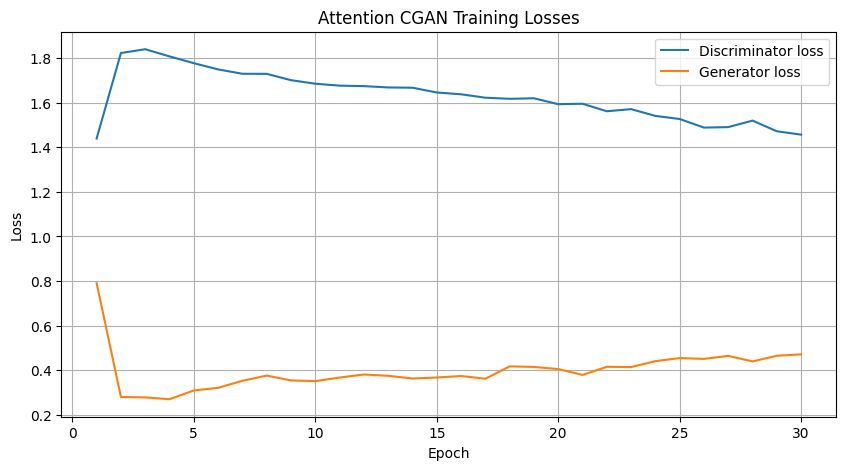

 epoch   d_loss   g_loss
    21 1.595091 0.378663
    22 1.561481 0.415003
    23 1.570982 0.413792
    24 1.540610 0.440380
    25 1.526638 0.454239
    26 1.488179 0.450414
    27 1.490368 0.464026
    28 1.519549 0.439211
    29 1.471595 0.464599
    30 1.456531 0.470836


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

LOG_PATH = V2_DIR / "training_losses.csv"

losses = pd.read_csv(LOG_PATH)

plt.figure(figsize=(10, 5))
plt.plot(losses["epoch"], losses["d_loss"], label="Discriminator loss")
plt.plot(losses["epoch"], losses["g_loss"], label="Generator loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Attention CGAN Training Losses")
plt.legend()
plt.grid(True)
plt.show()

print(losses.tail(10).to_string(index=False))

Fixed noise and labels at epochs 5-30:

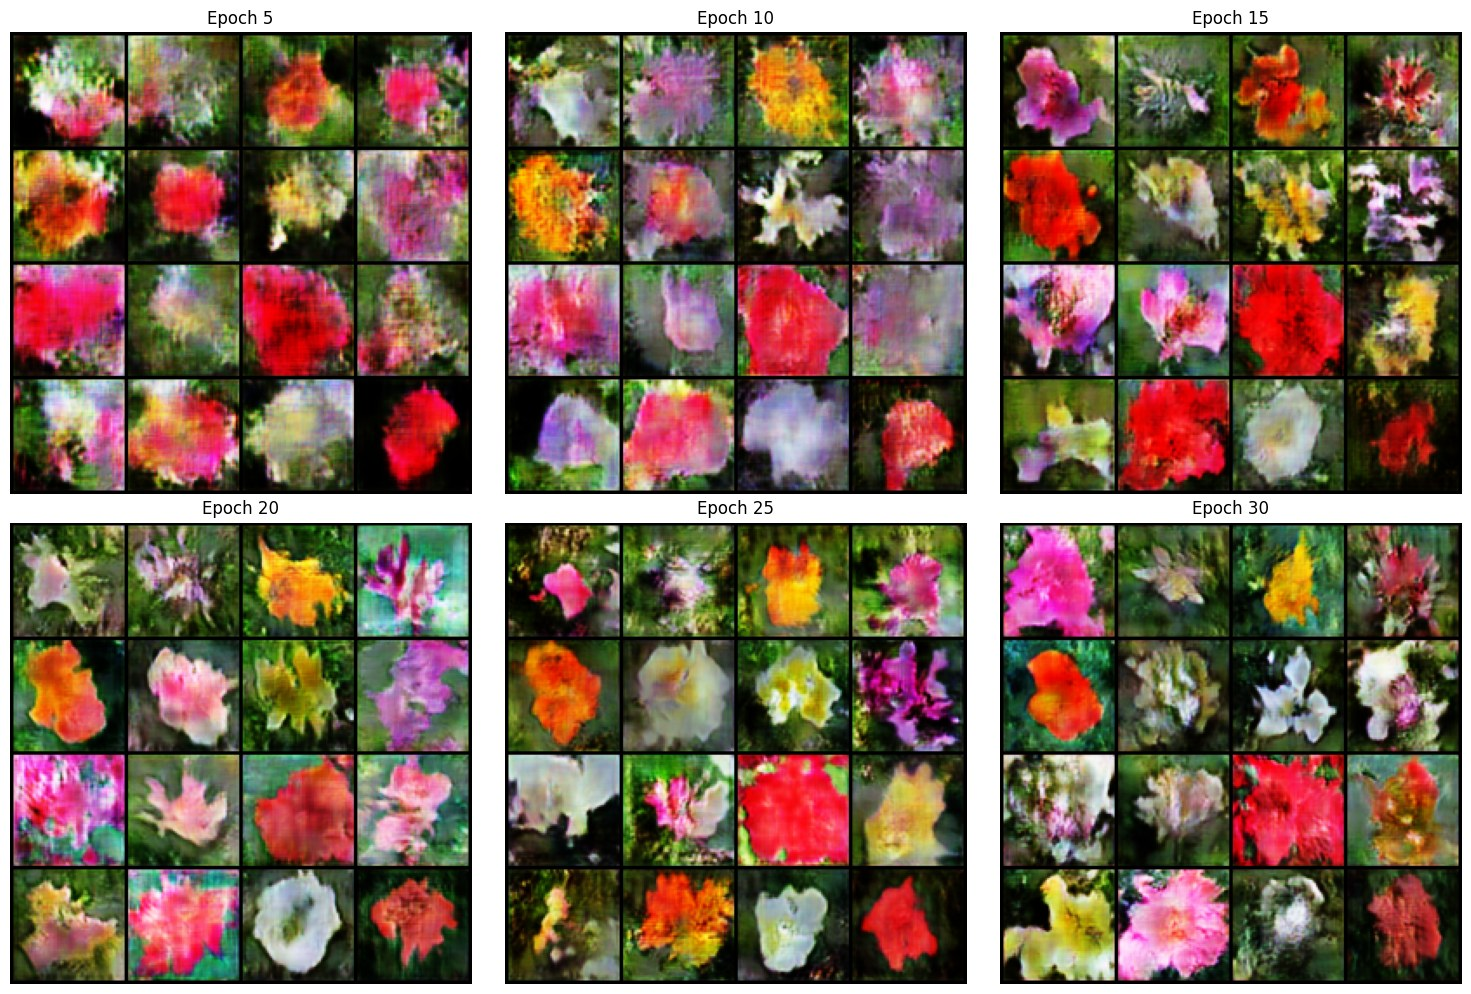

In [ ]:
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from torchvision.utils import make_grid

CHECKPOINT_DIR = V2_DIR / "checkpoints"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

epochs = [5, 10, 15, 20, 25, 30]

# Use identical noise and labels for every checkpoint
torch.manual_seed(123)
z = torch.randn(16, 128, device=DEVICE)
labels = torch.arange(16, device=DEVICE) % 40

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for ax, epoch in zip(axes.flat, epochs):
    checkpoint_path = CHECKPOINT_DIR / f"generator_epoch_{epoch}.pt"

    # Create a fresh generator for each checkpoint
    model = AttnGenerator().to(DEVICE)
    state = torch.load(
        checkpoint_path, map_location=DEVICE, weights_only=True
    )
    model.load_state_dict(state)
    model.eval()

    with torch.no_grad():
        images = model(z, labels).cpu()
        images = (images.clamp(-1, 1) + 1) / 2

    grid = make_grid(images, nrow=4, padding=2)
    ax.imshow(grid.permute(1, 2, 0).numpy())
    ax.set_title(f"Epoch {epoch}")
    ax.axis("off")

plt.tight_layout()
plt.show()

Same noise vector, all 40 class labels (epoch 30). Only the label changes between images:

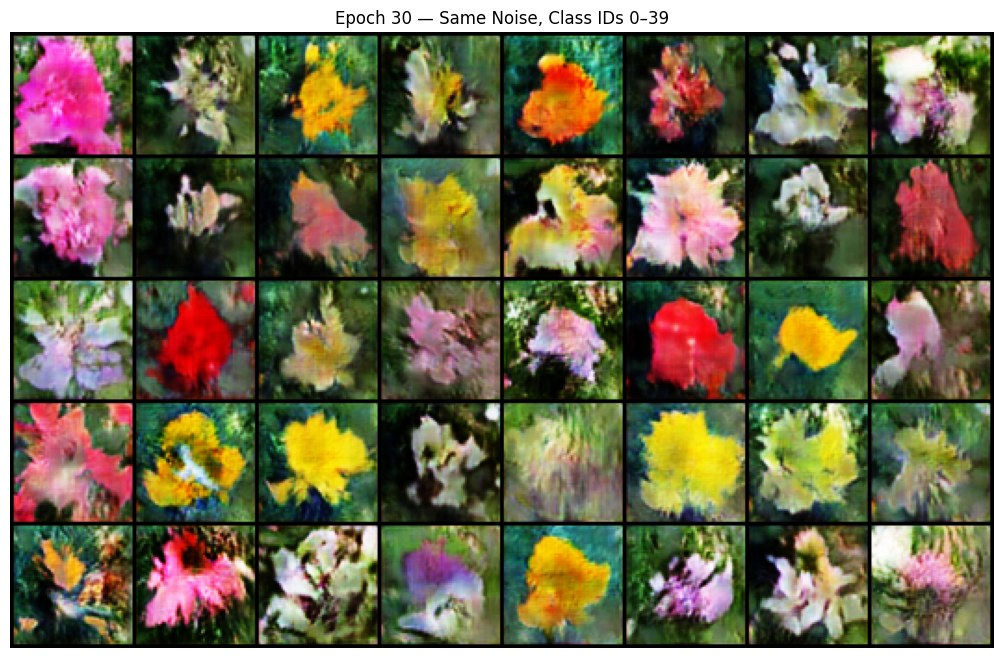

In [ ]:
import torch
import matplotlib.pyplot as plt
from torchvision.utils import make_grid

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT = CHECKPOINT_DIR / "generator_epoch_30.pt"

# Load the trained generator
G = AttnGenerator().to(DEVICE)
state = torch.load(CHECKPOINT, map_location=DEVICE, weights_only=True)
G.load_state_dict(state)
G.eval()

# Keep noise identical; vary only the class labels
torch.manual_seed(123)
z = torch.randn(1, 128, device=DEVICE).repeat(40, 1)
labels = torch.arange(40, device=DEVICE)

with torch.no_grad():
    images = G(z, labels).cpu()
    images = (images.clamp(-1, 1) + 1) / 2

grid = make_grid(images, nrow=8, padding=2)

plt.figure(figsize=(14, 8))
plt.imshow(grid.permute(1, 2, 0))
plt.title("Epoch 30 — Same Noise, Class IDs 0–39")
plt.axis("off")
plt.show()

Real flowers vs generated flowers with the same labels:

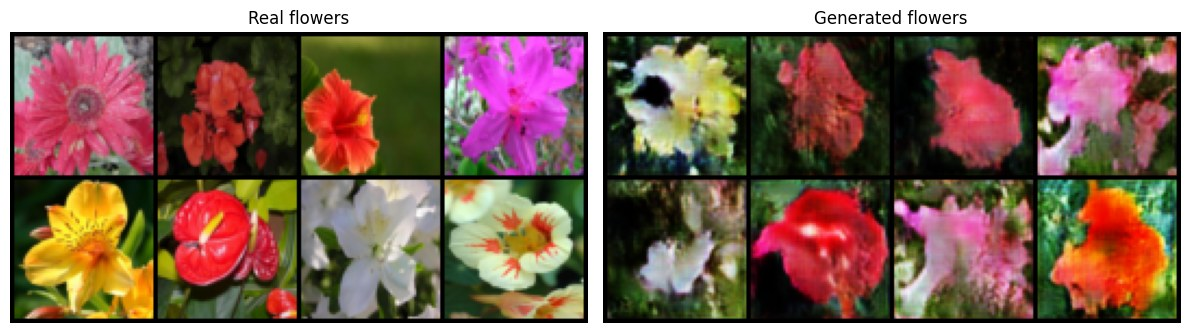

In [ ]:
import matplotlib.pyplot as plt
import torch
from torchvision.utils import make_grid

G.eval()

# Real images
real_images, real_labels = next(iter(loader))
real_images = real_images[:8].to(DEVICE)

# Generated images with the same class labels
labels = real_labels[:8].to(DEVICE)
z = torch.randn(8, 128, device=DEVICE)

with torch.no_grad():
    fake_images = G(z, labels)

real_grid = make_grid(
    (real_images.cpu() + 1) / 2, nrow=4, padding=2
)
fake_grid = make_grid(
    (fake_images.cpu().clamp(-1, 1) + 1) / 2,
    nrow=4, padding=2
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(real_grid.permute(1, 2, 0))
axes[0].set_title("Real flowers")
axes[0].axis("off")

axes[1].imshow(fake_grid.permute(1, 2, 0))
axes[1].set_title("Generated flowers")
axes[1].axis("off")

plt.tight_layout()
plt.show()

Four noise vectors for each of five classes (class ID: name):

In [ ]:
import torch
import matplotlib.pyplot as plt

G.eval()
device = next(G.parameters()).device

# Pick 5 representative classes
selected_classes = [0, 1, 5, 10, 39]
num_samples = 4

torch.manual_seed(123)
z = torch.randn(num_samples, 128, device=device)

fig, axes = plt.subplots(
    len(selected_classes), num_samples,
    figsize=(10, 12)
)

with torch.no_grad():
    for row, class_id in enumerate(selected_classes):
        labels = torch.full(
            (num_samples,), class_id,
            dtype=torch.long, device=device
        )
        generated = G(z, labels)
        generated = (generated.cpu().clamp(-1, 1) + 1) / 2

        for col in range(num_samples):
            axes[row, col].imshow(
                generated[col].permute(1, 2, 0)
            )
            axes[row, col].set_title(f"{class_id}: {class_names[class_id]}", fontsize=9)
            axes[row, col].axis("off")

plt.suptitle("Generated samples across classes and noise vectors")
plt.tight_layout()
plt.show()

### 5.5 Text cross-attention over CLIP token embeddings

Each class has a text description (`a photograph of a <name> flower`) encoded by the frozen CLIP text encoder from Task 3 into a (77 x 512) token matrix.
A `TextCrossAttention` layer lets the 16x16 image features (queries) attend over those text tokens (keys/values), and is inserted after the self-attention layer. A learnable gate (`gamma`, initialised at 0) controls how much text information is mixed in.

In [ ]:
def encode_prompts(prompts):
    """Tokenize prompts and return CLIP token embeddings of shape (batch, 77, 512)."""
    tokens = tokenizer(
        prompts,
        padding="max_length",
        truncation=True,
        max_length=tokenizer.model_max_length,
        return_tensors="pt"
    ).to(DEVICE)
    with torch.no_grad():
        return text_encoder(**tokens).last_hidden_state

print("Embedding shape:", tuple(encode_prompts(["a photograph of a red rose"]).shape))

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class TextCrossAttention(nn.Module):
    def __init__(self, image_channels=128, text_dim=512, attention_dim=128):
        super().__init__()

        self.query = nn.Conv2d(image_channels, attention_dim, kernel_size=1)
        self.key = nn.Linear(text_dim, attention_dim)
        self.value = nn.Linear(text_dim, image_channels)
        self.gamma = nn.Parameter(torch.zeros(1))

    def forward(self, image_features, text_tokens):
        # image_features: (B, 128, H, W)
        # text_tokens:    (B, 77, 512)
        batch, channels, height, width = image_features.shape
        positions = height * width

        queries = self.query(image_features)
        queries = queries.flatten(2).transpose(1, 2)  # (B, HW, 128)

        keys = self.key(text_tokens)                   # (B, 77, 128)
        values = self.value(text_tokens)               # (B, 77, 128)

        scores = torch.bmm(queries, keys.transpose(1, 2))
        scores = scores / (queries.shape[-1] ** 0.5)
        attention = torch.softmax(scores, dim=-1)

        attended = torch.bmm(attention, values)
        attended = attended.transpose(1, 2).reshape(
            batch, channels, height, width
        )

        return image_features + self.gamma * attended

In [ ]:
cross_attn = TextCrossAttention().to(DEVICE)

test_images = torch.randn(2, 128, 16, 16, device=DEVICE)
test_text = encode_prompts([
    "a photograph of a red rose",
    "a photograph of a yellow flower"
])

with torch.no_grad():
    test_output = cross_attn(test_images, test_text)

print("Input shape:", tuple(test_images.shape))
print("Text shape:", tuple(test_text.shape))
print("Output shape:", tuple(test_output.shape))
print("Cross-attention layer is working.")

Input shape: (2, 128, 16, 16)
Text shape: (2, 77, 512)
Output shape: (2, 128, 16, 16)
Cross-attention layer is working.


In [ ]:
import copy
import torch
import torch.nn as nn

class TextConditionedGenerator(nn.Module):
    def __init__(self, base_generator):
        super().__init__()

        # Copy the original architecture and weights.
        self.label_emb = copy.deepcopy(base_generator.label_emb)
        self.fc = copy.deepcopy(base_generator.fc)
        self.b1 = copy.deepcopy(base_generator.b1)
        self.b2 = copy.deepcopy(base_generator.b2)
        self.attn = copy.deepcopy(base_generator.attn)
        self.b3 = copy.deepcopy(base_generator.b3)
        self.b4 = copy.deepcopy(base_generator.b4)
        self.out = copy.deepcopy(base_generator.out)

        # New text cross-attention layer.
        self.text_attn = TextCrossAttention(
            image_channels=128,
            text_dim=512,
            attention_dim=128
        )

    def forward(self, z, labels, text_tokens):
        y = self.label_emb(labels)
        x = self.fc(torch.cat([z, y], dim=1))
        x = x.view(-1, 256, 4, 4)

        x = self.b1(x)
        x = self.b2(x)

        # Existing visual self-attention.
        x = self.attn(x)

        # New text cross-attention.
        x = self.text_attn(x, text_tokens)

        x = self.b3(x)
        x = self.b4(x)
        return self.out(x)


G_text = TextConditionedGenerator(G).to(DEVICE)

print("New text-conditioned generator created.")
print("Original generator remains unchanged.")
print("Cross-attention:", G_text.text_attn)

New text-conditioned generator created.
Original generator remains unchanged.
Cross-attention: TextCrossAttention(
  (query): Conv2d(128, 128, kernel_size=(1, 1), stride=(1, 1))
  (key): Linear(in_features=512, out_features=128, bias=True)
  (value): Linear(in_features=512, out_features=128, bias=True)
)


In [ ]:
G_text.eval()

test_labels = torch.tensor([5, 10], dtype=torch.long, device=DEVICE)
test_z = torch.randn(2, 128, device=DEVICE)

test_text = encode_prompts([
    "a photograph of a rose",
    "a photograph of a hibiscus"
])

with torch.no_grad():
    generated = G_text(test_z, test_labels, test_text)

print("Generated image shape:", tuple(generated.shape))
print("Minimum pixel value:", generated.min().item())
print("Maximum pixel value:", generated.max().item())

Generated image shape: (2, 3, 64, 64)
Minimum pixel value: -0.999428927898407
Maximum pixel value: 0.9858424067497253


Cache one CLIP embedding per class description:

In [ ]:
embedding_path = V2_DIR / "class_text_embeddings.pt"

# make_prompt() is defined in section 4.2
prompts = {
    class_id: make_prompt(name)
    for class_id, name in class_names.items()
}

prompt_list = [prompts[i] for i in range(40)]
all_embeddings = []

with torch.no_grad():
    for start in range(0, 40, 8):
        all_embeddings.append(
            encode_prompts(prompt_list[start:start + 8]).cpu()
        )

class_text_embeddings = torch.cat(all_embeddings, dim=0)

torch.save({
    "class_names": class_names,
    "prompts": prompts,
    "embeddings": class_text_embeddings
}, embedding_path)

print("Updated embedding shape:", tuple(class_text_embeddings.shape))
for i in range(5):
    print(i, "->", prompts[i])

Updated embedding shape: (40, 77, 512)
0 -> a photograph of a petunia flower
1 -> a photograph of a passion flower
2 -> a photograph of a wallflower
3 -> a photograph of a water lily flower
4 -> a photograph of a watercress flower


### 5.6 Train the text-conditioned generator (5 epochs, starting from the 30-epoch self-attention weights)

In [ ]:
TEXT_RUN_DIR = str(OUTPUTS / "task5_text_cross_attention")
TEXT_CKPT_DIR = os.path.join(TEXT_RUN_DIR, "checkpoints")
TEXT_SAMPLE_DIR = os.path.join(TEXT_RUN_DIR, "samples")
os.makedirs(TEXT_CKPT_DIR, exist_ok=True)
os.makedirs(TEXT_SAMPLE_DIR, exist_ok=True)

opt_G_text = torch.optim.Adam(
    G_text.parameters(),
    lr=0.0001,
    betas=(0.0, 0.9)
)

opt_D_text = torch.optim.Adam(
    D.parameters(),
    lr=0.0002,
    betas=(0.0, 0.9)
)

LATENT_DIM = 128
NUM_CLASSES = 40
TEXT_EPOCHS = 5

# Fixed samples make epoch-to-epoch comparisons easier.
fixed_labels = torch.arange(0, 40, device=DEVICE)
fixed_z = torch.randn(40, LATENT_DIM, device=DEVICE)

# Dataset class IDs must match the cached text-embedding indices.
embedding_bank = class_text_embeddings.to(DEVICE)

def get_text_for_labels(labels):
    return embedding_bank[labels.long()]

history = []

for epoch in range(1, TEXT_EPOCHS + 1):
    G_text.train()
    D.train()

    total_d_loss = 0.0
    total_g_loss = 0.0
    batches = 0

    for real_images, labels in loader:
        real_images = real_images.to(DEVICE)
        labels = labels.to(DEVICE).long()
        batch_size = real_images.size(0)

        text_tokens = get_text_for_labels(labels)

        # -------------------------
        # Train discriminator
        # -------------------------
        opt_D_text.zero_grad(set_to_none=True)

        z = torch.randn(batch_size, LATENT_DIM, device=DEVICE)
        with torch.no_grad():
            fake_images = G_text(z, labels, text_tokens)

        real_scores = D(real_images, labels)
        fake_scores = D(fake_images, labels)

        d_loss = (
            F.relu(1.0 - real_scores).mean()
            + F.relu(1.0 + fake_scores).mean()
        )

        d_loss.backward()
        opt_D_text.step()

        # -------------------------
        # Train generator
        # -------------------------
        opt_G_text.zero_grad(set_to_none=True)

        z = torch.randn(batch_size, LATENT_DIM, device=DEVICE)
        fake_images = G_text(z, labels, text_tokens)
        fake_scores = D(fake_images, labels)

        g_loss = -fake_scores.mean()

        g_loss.backward()
        opt_G_text.step()

        total_d_loss += d_loss.item()
        total_g_loss += g_loss.item()
        batches += 1

    avg_d = total_d_loss / batches
    avg_g = total_g_loss / batches
    gamma = G_text.text_attn.gamma.item()

    history.append({
        "epoch": epoch,
        "d_loss": avg_d,
        "g_loss": avg_g,
        "cross_attention_gamma": gamma
    })

    print(
        f"Epoch {epoch}/{TEXT_EPOCHS} | "
        f"D: {avg_d:.4f} | G: {avg_g:.4f} | "
        f"cross-attention gamma: {gamma:.6f}"
    )

    # Save a checkpoint each epoch.
    torch.save({
        "epoch": epoch,
        "generator": G_text.state_dict(),
        "discriminator": D.state_dict(),
        "optimizer_G": opt_G_text.state_dict(),
        "optimizer_D": opt_D_text.state_dict(),
        "history": history,
        "class_names": class_names,
        "prompts": prompts
    }, os.path.join(TEXT_CKPT_DIR, f"epoch_{epoch}.pt"))

    # Save one generated image per class.
    G_text.eval()
    with torch.no_grad():
        fixed_text = get_text_for_labels(fixed_labels)
        samples = G_text(fixed_z, fixed_labels, fixed_text)

        save_image(
            (samples.clamp(-1, 1) + 1) / 2,
            os.path.join(TEXT_SAMPLE_DIR, f"epoch_{epoch}.png"),
            nrow=8
        )

print("Training finished.")
print("Checkpoints:", TEXT_CKPT_DIR)
print("Samples:", TEXT_SAMPLE_DIR)

Epoch 1/5 | D: 1.4940 | G: 0.4806 | cross-attention gamma: 0.010749
Epoch 2/5 | D: 1.4860 | G: 0.5113 | cross-attention gamma: 0.020394
Epoch 3/5 | D: 1.5048 | G: 0.4918 | cross-attention gamma: 0.026558
Epoch 4/5 | D: 1.4947 | G: 0.5163 | cross-attention gamma: 0.034358
Epoch 5/5 | D: 1.4753 | G: 0.5155 | cross-attention gamma: 0.039620
Training finished.
Checkpoints: /content/drive/MyDrive/ElevanceSkills_Project/outputs/task5_text_cross_attention/checkpoints
Samples: /content/drive/MyDrive/ElevanceSkills_Project/outputs/task5_text_cross_attention/samples


In [ ]:
final_checkpoint_path = os.path.join(
    TEXT_CKPT_DIR, "final_text_conditioned_gan.pt"
)

torch.save({
    "generator": G_text.state_dict(),
    "discriminator": D.state_dict(),
    "optimizer_G": opt_G_text.state_dict(),
    "optimizer_D": opt_D_text.state_dict(),
    "class_names": class_names,
    "prompts": prompts,
    "training_history": history,
}, final_checkpoint_path)

print("Final checkpoint saved:")
print(final_checkpoint_path)
print("File exists:", os.path.exists(final_checkpoint_path))



import pandas as pd

history_path = os.path.join(TEXT_RUN_DIR, "training_history.csv")
pd.DataFrame(history).to_csv(history_path, index=False)

print("Training history saved:", history_path)

Final checkpoint saved:
/content/drive/MyDrive/ElevanceSkills_Project/outputs/task5_text_cross_attention/checkpoints/final_text_conditioned_gan.pt
File exists: True


Training history saved: /content/drive/MyDrive/ElevanceSkills_Project/outputs/task5_text_cross_attention/training_history.csv


### 5.7 Ablation: does attention help?

To measure what the attention layers add, four generators are compared on the same 40-class data. All use the same hinge loss, optimisers, batch size and seed as section 5.3:

| # | Generator | Epochs |
|---|---|---|
| 1 | No attention (`use_self_attention=False`) | 30 |
| 2 | Self-attention (section 5.3) | 30 |
| 3 | Self-attention, trained 5 more epochs (control) | 35 |
| 4 | Self-attention + text cross-attention (section 5.6) | 30 + 5 |

Model 3 is the fair reference for model 4, because model 4 had 5 extra epochs of training. Quality is measured with the Fréchet Inception Distance (FID, lower is better) between generated and real images. Treat small FID differences with care: each model is trained once, on 64x64 images, and FID is noisy at this scale.

In [ ]:
import pandas as pd
from torch.utils.data import DataLoader

ABL_DIR = OUTPUTS / "task5_attention_ablation"
ABL_DIR.mkdir(parents=True, exist_ok=True)


def train_hinge_gan(gen, disc, epochs, tag):
    """Same recipe as section 5.3: hinge loss, G lr 1e-4, D lr 2e-4, Adam betas (0.0, 0.9)."""
    opt_g = torch.optim.Adam(gen.parameters(), lr=0.0001, betas=(0.0, 0.9))
    opt_d = torch.optim.Adam(disc.parameters(), lr=0.0002, betas=(0.0, 0.9))
    shuffle_gen = torch.Generator()
    shuffle_gen.manual_seed(SEED)
    train_loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
                              num_workers=2, pin_memory=True, generator=shuffle_gen)
    history = []
    for epoch in range(1, epochs + 1):
        gen.train()
        disc.train()
        d_total, g_total, count = 0.0, 0.0, 0
        for real, real_y in train_loader:
            real = real.to(DEVICE, non_blocking=True)
            real_y = real_y.to(DEVICE, non_blocking=True)
            n = real.size(0)

            # discriminator step
            z = torch.randn(n, LATENT_DIM, device=DEVICE)
            fake_y = torch.randint(NUM_CLASSES, (n,), device=DEVICE)
            with torch.no_grad():
                fake = gen(z, fake_y)
            d_loss = (F.relu(1 - disc(real, real_y)).mean()
                      + F.relu(1 + disc(fake, fake_y)).mean())
            opt_d.zero_grad(set_to_none=True)
            d_loss.backward()
            opt_d.step()

            # generator step (discriminator weights frozen)
            for p in disc.parameters():
                p.requires_grad_(False)
            z = torch.randn(n, LATENT_DIM, device=DEVICE)
            gen_y = torch.randint(NUM_CLASSES, (n,), device=DEVICE)
            g_loss = -disc(gen(z, gen_y), gen_y).mean()
            opt_g.zero_grad(set_to_none=True)
            g_loss.backward()
            opt_g.step()
            for p in disc.parameters():
                p.requires_grad_(True)

            d_total += d_loss.item()
            g_total += g_loss.item()
            count += 1

        history.append({"epoch": epoch, "d_loss": d_total / count, "g_loss": g_total / count})
        print(f"[{tag}] epoch {epoch}/{epochs} | D: {d_total / count:.4f} | G: {g_total / count:.4f}")

    history = pd.DataFrame(history)
    history.to_csv(ABL_DIR / f"{tag}_losses.csv", index=False)
    torch.save(gen.state_dict(), ABL_DIR / f"{tag}_generator.pt")
    return history


# Model 1: identical generator without the self-attention layer, trained from scratch for 30 epochs
assert torch.cuda.is_available(), "Enable a GPU runtime in Colab."
torch.manual_seed(SEED)
G_noattn = AttnGenerator(use_self_attention=False).to(DEVICE)
D_noattn = AttnDiscriminator().to(DEVICE)
hist_noattn = train_hinge_gan(G_noattn, D_noattn, EPOCHS, "no_attention")

In [ ]:
# Model 3 (control): continue the 30-epoch self-attention GAN for the same 5 extra epochs that the text-conditioned GAN received
G_ctrl = AttnGenerator().to(DEVICE)
D_ctrl = AttnDiscriminator().to(DEVICE)
G_ctrl.load_state_dict(torch.load(CHECKPOINT_DIR / "generator_epoch_30.pt", map_location=DEVICE, weights_only=True))
D_ctrl.load_state_dict(torch.load(CHECKPOINT_DIR / "discriminator_epoch_30.pt", map_location=DEVICE, weights_only=True))
hist_ctrl = train_hinge_gan(G_ctrl, D_ctrl, TEXT_EPOCHS, "self_attention_plus5")

# Model 2: the 30-epoch self-attention generator saved in section 5.3
G_selfattn = AttnGenerator().to(DEVICE)
G_selfattn.load_state_dict(torch.load(V2_DIR / "attention_generator_final.pt", map_location=DEVICE, weights_only=True))

# Every model, as a function (noise, labels) -> images in [-1, 1]
ablation_models = {
    "1. No attention (30 ep)":                     (G_noattn,   lambda z, y: G_noattn(z, y),                    30),
    "2. Self-attention (30 ep)":                   (G_selfattn, lambda z, y: G_selfattn(z, y),                  30),
    "3. Self-attention (35 ep, control)":          (G_ctrl,     lambda z, y: G_ctrl(z, y),                      35),
    "4. Self + text cross-attention (30+5 ep)":    (G_text,     lambda z, y: G_text(z, y, embedding_bank[y]),   35),
}
for generator_model, _, _ in ablation_models.values():
    generator_model.eval()
print("Models ready:", list(ablation_models))

In [ ]:
# Fréchet Inception Distance: generated images vs the real 64x64 training images (lower is better)
from torchmetrics.image.fid import FrechetInceptionDistance

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])
eval_dataset = FlowerDataset40(df, transform=eval_transform)
FID_BATCH_SIZE = 100
eval_loader = DataLoader(eval_dataset, batch_size=FID_BATCH_SIZE, shuffle=False, num_workers=2)
eval_labels = torch.tensor(df["class_id"].values, dtype=torch.long)    # generate the same class mix as the real data


def to_unit(x):
    return ((x.float().clamp(-1, 1) + 1) / 2).to(DEVICE)


fid_metric = FrechetInceptionDistance(feature=2048, reset_real_features=False, normalize=True).to(DEVICE)
with torch.no_grad():
    for real_batch, _ in eval_loader:
        fid_metric.update(to_unit(real_batch), real=True)


@torch.no_grad()
def fid_of(generate_fn, seed=0):
    noise_gen = torch.Generator(device="cpu").manual_seed(seed)     # same noise for every model
    for start in range(0, len(eval_labels), FID_BATCH_SIZE):
        labels = eval_labels[start:start + FID_BATCH_SIZE].to(DEVICE)
        z = torch.randn(len(labels), LATENT_DIM, generator=noise_gen).to(DEVICE)
        fid_metric.update(to_unit(generate_fn(z, labels)), real=False)
    score = float(fid_metric.compute())
    fid_metric.reset()                  # keeps the cached statistics of the real images
    return score


rows = []
for name, (generator_model, generate_fn, epochs) in ablation_models.items():
    rows.append({
        "Model": name,
        "Epochs": epochs,
        "Generator parameters": sum(p.numel() for p in generator_model.parameters()),
        "FID (lower is better)": round(fid_of(generate_fn), 2),
    })
    print("done:", name)

ablation_df = pd.DataFrame(rows)
ablation_df.to_csv(ABL_DIR / "ablation_fid.csv", index=False)
display(ablation_df)

In [ ]:
# Same noise and labels for every model, plus real images of the same classes
vis_ids = [0, 5, 9, 15, 20, 25, 30, 35]
torch.manual_seed(123)
vis_z = torch.randn(len(vis_ids), LATENT_DIM, device=DEVICE)
vis_y = torch.tensor(vis_ids, dtype=torch.long, device=DEVICE)

real_ref = torch.stack([
    eval_dataset[int(np.flatnonzero(df["class_id"].values == c)[0])][0] for c in vis_ids
])
rows_to_plot = {"Real images": real_ref}
with torch.no_grad():
    for name, (_, generate_fn, _) in ablation_models.items():
        rows_to_plot[name] = generate_fn(vis_z, vis_y).cpu()

fig, axes = plt.subplots(len(rows_to_plot), 1, figsize=(15, 2.3 * len(rows_to_plot)))
for ax, (name, images) in zip(axes, rows_to_plot.items()):
    grid = make_grid((images.clamp(-1, 1) + 1) / 2, nrow=len(vis_ids), padding=2)
    ax.imshow(grid.permute(1, 2, 0))
    ax.set_title(name, fontsize=10, loc="left")
    ax.axis("off")
plt.suptitle("Columns = classes " + ", ".join(f"{i}: {class_names[i]}" for i in vis_ids), fontsize=9)
plt.tight_layout()
plt.show()

# Training losses: no attention vs self-attention
self_attn_losses = pd.read_csv(V2_DIR / "training_losses.csv")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, column, title in zip(axes, ["d_loss", "g_loss"], ["Discriminator hinge loss", "Generator loss"]):
    ax.plot(hist_noattn["epoch"], hist_noattn[column], label="No attention")
    ax.plot(self_attn_losses["epoch"], self_attn_losses[column], label="Self-attention")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.grid(True)
    ax.legend()
plt.tight_layout()
plt.show()

---
# Task 6 — End-to-end text-to-image pipeline

The pipeline chains every component built above:

1. **Text preprocessing** — CLIP tokenizer (Task 3) turns the prompt into 77 token IDs.
2. **Text embedding** — frozen CLIP text encoder produces a (77 x 512) embedding.
3. **Conditioning** — the flower class is resolved from the prompt: if the prompt contains one of the 40 flower names, that class is used; otherwise the class whose description is closest to the prompt in CLIP text space is chosen (a heuristic, limited to the 40 trained classes).
4. **GAN generation** — the attention GAN (self-attention + text cross-attention, Task 5) generates a 64x64 image from noise, class ID and the text embedding.
5. **Post-processing** — bicubic upscaling and saving. The GAN itself generates 64x64; upscaling only enlarges the image and adds no detail (`output_size=64` keeps the native resolution).

### 6.1 Load the trained text-conditioned GAN from its saved checkpoint

In [ ]:
CHECKPOINT_PATH = OUTPUTS / "task5_text_cross_attention" / "checkpoints" / "final_text_conditioned_gan.pt"
assert CHECKPOINT_PATH.is_file(), f"Checkpoint not found: {CHECKPOINT_PATH}"

checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)

G_text = TextConditionedGenerator(AttnGenerator()).to(DEVICE)
G_text.load_state_dict(checkpoint["generator"], strict=True)
G_text.eval()

class_names = checkpoint["class_names"]      # {class_id: flower name}
prompts = checkpoint["prompts"]              # {class_id: description}

print("Checkpoint loaded | classes:", len(class_names),
      "| training epochs recorded:", len(checkpoint["training_history"]))
print("Examples:", list(class_names.items())[:5])

### 6.2 Text preprocessing and embedding

In [ ]:
def preprocess_prompt(prompt):
    """Prompt -> CLIP token IDs -> (1, 77, 512) text embedding."""
    inputs = tokenizer(prompt, padding="max_length", truncation=True,
                       max_length=77, return_tensors="pt")
    inputs = {key: value.to(DEVICE) for key, value in inputs.items()}
    with torch.no_grad():
        embeddings = text_encoder(**inputs).last_hidden_state
    assert embeddings.shape == (1, 77, 512)
    return embeddings

### 6.3 Baseline (self-attention only) vs text-conditioned GAN, same noise and labels

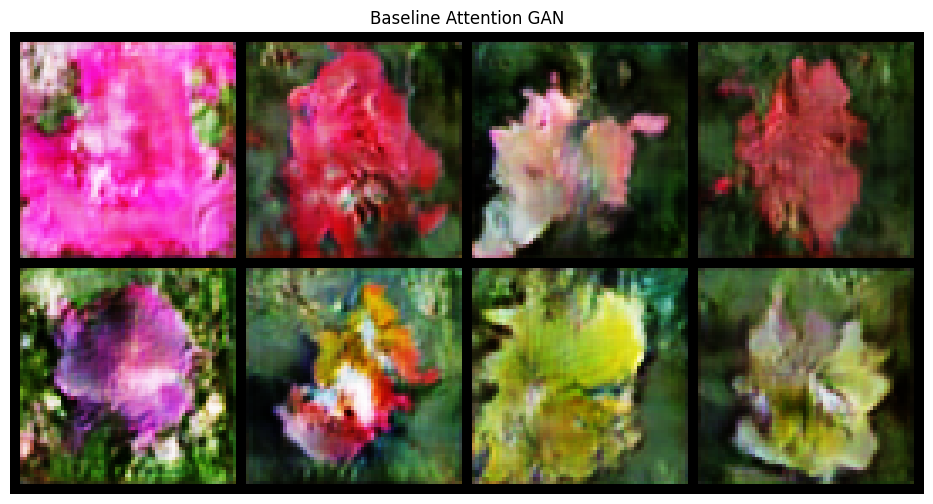

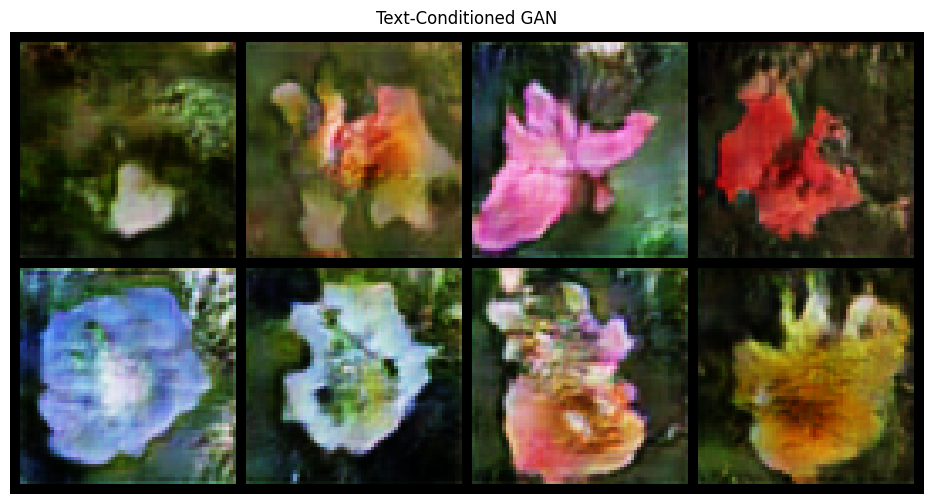

Baseline range: -0.9984428286552429 0.9986110329627991
Text-conditioned range: -0.9991211891174316 0.9562946557998657


In [ ]:
import torch
import matplotlib.pyplot as plt
from torchvision.utils import make_grid

BASE_DIR = V2_DIR

# Instantiate using the actual constructor
G_base = AttnGenerator().to(DEVICE)

# Load trained baseline weights
state = torch.load(
    f"{BASE_DIR}/attention_generator_final.pt",
    map_location=DEVICE,
    weights_only=True
)
G_base.load_state_dict(state)
G_base.eval()
G_text.eval()

# Generate both models' outputs using identical noise and labels
test_ids = [0, 5, 9, 15, 20, 25, 30, 35]
test_ids = [i for i in test_ids if i in class_names]

torch.manual_seed(42)
z = torch.randn(len(test_ids), LATENT_DIM, device=DEVICE)
labels = torch.tensor(test_ids, dtype=torch.long, device=DEVICE)

test_prompts = [
    f"a photograph of a {class_names[i]} flower"
    for i in test_ids
]
text_tokens = torch.cat(
    [preprocess_prompt(p) for p in test_prompts],
    dim=0
)

with torch.no_grad():
    baseline_images = G_base(z, labels).cpu()
    text_images = G_text(z, labels, text_tokens).cpu()

def display_images(images, title):
    grid = make_grid((images + 1) / 2, nrow=4, padding=3)
    plt.figure(figsize=(12, 6))
    plt.imshow(grid.permute(1, 2, 0).clamp(0, 1))
    plt.title(title)
    plt.axis("off")
    plt.show()

display_images(baseline_images, "Baseline Attention GAN")
display_images(text_images, "Text-Conditioned GAN")

print("Baseline range:",
      baseline_images.min().item(), baseline_images.max().item())
print("Text-conditioned range:",
      text_images.min().item(), text_images.max().item())

### 6.4 The pipeline: `generate_flower(prompt)`

`resolve_class` picks the flower class (name in the prompt, otherwise closest class by CLIP text similarity); `generate_flower` then embeds the prompt with CLIP, runs the text-conditioned GAN and saves the image.

In [ ]:
import os
import re
import textwrap
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image

# --------------------------------------------------
# 1. Configure output directories
# --------------------------------------------------

OUTPUT_DIR = str(OUTPUTS / "task6_integrated_pipeline")

SAMPLES_DIR = os.path.join(OUTPUT_DIR, "generated_samples")

os.makedirs(SAMPLES_DIR, exist_ok=True)


# --------------------------------------------------
# 2. Class lookup: flower name -> class ID, and CLIP embeddings of the class descriptions
# --------------------------------------------------

def clean_name(name):
    """Same cleaning as the training prompts (make_prompt)."""
    return str(name).replace("?", "").strip().lower()


name_to_id = {clean_name(name): int(class_id) for class_id, name in class_names.items()}


def pooled_text_embedding(text):
    """Unit-length CLIP sentence embedding of a text, shape (1, 512)."""
    inputs = tokenizer(text, padding="max_length", truncation=True,
                       max_length=77, return_tensors="pt")
    inputs = {key: value.to(DEVICE) for key, value in inputs.items()}
    with torch.no_grad():
        pooled = text_encoder(**inputs).pooler_output
    return F.normalize(pooled, dim=-1)


class_id_list = sorted(int(i) for i in class_names)
class_embeddings = torch.cat([pooled_text_embedding(prompts[i]) for i in class_id_list])   # (40, 512)


def resolve_class(prompt):
    """Return (class_id, flower_name, how_it_was_chosen) for a text prompt.

    1. A flower name inside the prompt wins (longest name if several match).
    2. Otherwise the class whose description is closest to the prompt in CLIP text space is used.
    """
    prompt_lower = prompt.lower()
    matches = [name for name in name_to_id
               if re.search(r"\b" + re.escape(name) + r"\b", prompt_lower)]
    if matches:
        flower_name = max(matches, key=len)
        return name_to_id[flower_name], flower_name, "flower name found in prompt"

    similarity = (pooled_text_embedding(prompt) @ class_embeddings.T).squeeze(0)
    best = int(similarity.argmax())
    class_id = class_id_list[best]
    return (class_id, clean_name(class_names[class_id]),
            f"closest class by CLIP text similarity ({similarity[best].item():.3f})")


# --------------------------------------------------
# 3. Generate an image from a text prompt
# --------------------------------------------------

def generate_flower(prompt, seed=42, output_size=256, show=True, verbose=True):
    """
    Generate a flower image using the text-conditioned GAN.

    Args:
        prompt (str): Text describing the flower.
        seed (int): Random seed for reproducibility.
        output_size (int): Final image width and height (the GAN generates 64 x 64).
        show (bool): Display the image.
        verbose (bool): Print the pipeline metadata.

    Returns:
        PIL.Image: Generated RGB flower image.
    """

    if not isinstance(prompt, str) or not prompt.strip():
        raise ValueError("Please provide a non-empty text prompt.")
    if output_size < 1:
        raise ValueError("output_size must be a positive integer.")

    prompt = prompt.strip()

    # --------------------------------------------------
    # A. Resolve the flower class from the prompt
    # --------------------------------------------------

    class_id, flower_name, how = resolve_class(prompt)

    # --------------------------------------------------
    # B. Preprocess the prompt and create text embeddings
    # --------------------------------------------------

    text_embeddings = preprocess_prompt(prompt)

    if text_embeddings.shape != (1, 77, 512):
        raise ValueError(
            f"Unexpected text embedding shape: "
            f"{tuple(text_embeddings.shape)}"
        )

    # --------------------------------------------------
    # C. Create latent noise and class label
    # --------------------------------------------------

    random_generator = torch.Generator(device=DEVICE)
    random_generator.manual_seed(seed)

    z = torch.randn(
        1,
        LATENT_DIM,
        generator=random_generator,
        device=DEVICE
    )

    labels = torch.tensor(
        [class_id],
        dtype=torch.long,
        device=DEVICE
    )

    # --------------------------------------------------
    # D. Generate an image using the text-conditioned GAN
    # --------------------------------------------------

    G_text.eval()

    with torch.no_grad():
        generated = G_text(z, labels, text_embeddings)

    # Convert from [-1, 1] to [0, 1].
    image_tensor = ((generated[0:1].detach().float().cpu() + 1) / 2)
    image_tensor = image_tensor.clamp(0, 1)

    original_height = image_tensor.shape[2]
    original_width = image_tensor.shape[3]

    # --------------------------------------------------
    # E. Upscale the image
    # --------------------------------------------------

    if original_height != output_size or original_width != output_size:
        image_tensor = F.interpolate(
            image_tensor,
            size=(output_size, output_size),
            mode="bicubic",
            align_corners=False
        ).clamp(0, 1)

    # --------------------------------------------------
    # F. Convert the tensor into a PIL RGB image
    # --------------------------------------------------

    image_array = (
        image_tensor[0]
        .permute(1, 2, 0)
        .mul(255)
        .round()
        .byte()
        .numpy()
    )

    image = Image.fromarray(image_array)

    # --------------------------------------------------
    # G. Save the generated image
    # --------------------------------------------------

    safe_name = re.sub(
        r"[^a-zA-Z0-9_-]+",
        "_",
        flower_name
    ).strip("_")

    output_path = os.path.join(
        SAMPLES_DIR,
        f"{safe_name}_seed_{seed}_{output_size}px.png"
    )

    image.save(output_path)

    # --------------------------------------------------
    # H. Display results and metadata
    # --------------------------------------------------

    if verbose:
        print("Image generation completed.")
        print(f"Prompt: {prompt}")
        print(f"Flower class: {flower_name} ({how})")
        print(f"Class ID: {class_id}")
        print(f"Text embedding shape: {tuple(text_embeddings.shape)}")
        print(f"Original dimensions: {original_width} × {original_height}")
        print(f"Final dimensions: {image.width} × {image.height}")
        print(f"Saved to: {output_path}")

    if show:
        plt.figure(figsize=(6, 6))
        plt.imshow(image)
        plt.title(f"{flower_name.title()} — {image.width} × {image.height}")
        plt.axis("off")
        plt.show()

    return image


# --------------------------------------------------
# 4. Test the integrated text-to-image pipeline
# --------------------------------------------------

test_image = generate_flower(
    prompt="a photograph of a petunia flower",
    seed=42,
    output_size=256
)

print("Verified output size:", test_image.size)

Pipeline output for eight prompts. The first four contain a flower name; the last four are free-form descriptions without one, so the class is chosen by CLIP text similarity (a heuristic — the GAN only knows the 40 trained classes). Each title shows the class that was used:

In [ ]:
pipeline_prompts = [
    "a photograph of a petunia flower",
    "a photograph of a rose flower",
    "a close-up photo of a pink hibiscus in bloom",
    "a lotus floating on a calm pond",
    "a bright yellow flower with long petals",
    "a purple flower in a garden",
    "a large white flower",
    "an orange flower with many petals",
]

fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
for ax, prompt in zip(axes.flat, pipeline_prompts):
    class_id, flower_name, how = resolve_class(prompt)
    image = generate_flower(prompt, seed=100 + class_id, output_size=256, show=False, verbose=False)
    ax.imshow(image)
    ax.set_title(f"{textwrap.fill(prompt, 30)}\n→ {flower_name}", fontsize=8)
    ax.axis("off")
    print(f"{prompt!r:55} -> {flower_name} [{how}]")

plt.tight_layout()
plt.show()